# Ocular dominance with the common-regressor GLM (`glm_common`) - full investigation

**Method (chosen in `od_strategy_prfmodel.ipynb`):**

1. prfmodel CSS fits on percent-signal-change data, task `BarsBarsRingsWedges` (4 runs: Bars01, Bars02, Rings, Wedges), each eye fitted separately.
2. Vertex selection with the **prf_analysis filters** (`prf-analysis.yml`), applied to **both** eyes, plus a positive amplitude (needed for an OD ratio).
3. Common regressor, per run: the two eyes' predictions are z-scored, averaged and z-scored again → same response shape for both eyes.
4. GLM per eye (data of that eye on the common regressor, run means removed) → β and SE.
5. OD index = (β_L − β_R) / (β_L + β_R) per vertex, median per ROI and subject. Patients: converted to **fellow − amblyopic**; controls: right − left. z = (β_L − β_R) / √(SE_L² + SE_R²).

**Investigations:**

| section | question |
|---|---|
| 1 | Main result: patients vs controls per ROI |
| 2 | Run reliability: the three 2-vs-2 run splits, and single-run correlations (all run pairs), with Spearman-Brown prediction for 4 runs |
| 3 | Within-eye noise floor: how much "dominance" do run-to-run changes alone produce? |
| 4 | Per-subject permutation of the eye labels across the 8 runs |
| 5 | Relation with amblyopia depth (logMAR) |
| 6 | Supplementary: same analysis with each eye's own regressor (`glm_own`) |
| 7 | ROI summary: median OD vs R²-weighted OD vs inverse-variance-weighted OD vs median z |
| 8 | Flatmaps of the OD index (and of z) |

**Main ROIs: V1, V2, V3.** V4, V3A, V3B, LO1 and LO2 are shown as indicative (fewer vertices, lower pRF quality).

**Files written:** one cache file per subject in `/Users/uriel/Desktop/fig_od/od_glm_common_cache/` (per-run GLM sums of the ROI vertices). Section 8 also saves the flatmap patches and group panels in `/Users/uriel/Desktop/fig_od/glm_common/`. First run: ~2-3 min per subject, 6 subjects in parallel.

In [1]:
# Stop warnings
import warnings
warnings.filterwarnings("ignore")

# General imports
import os
import sys
import time
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed

# Personal imports
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from settings_utils import load_settings
from pycortex_utils import set_pycortex_config_file, get_rois
from surface_utils import load_surface

In [2]:
# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
cache_dir = '/Users/uriel/Desktop/fig_od/od_glm_common_cache'
use_cache = True                         # True = save/reload the extracted sums; False = re-read everything, save nothing
if use_cache:
    os.makedirs(cache_dir, exist_ok=True)

# Load settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
settings = load_settings([os.path.join(base_dir, project_dir, f) for f in
                          ["settings.yml", "prf-analysis.yml", "figure-settings.yml"]])
analysis_info = settings[0]
patients = analysis_info['group-patient']
controls = analysis_info['group-control']

# Pycortex database (for the ROIs)
cortex_dir = "{}/{}/derivatives/pp_data/cortex".format(main_dir, project_dir)
set_pycortex_config_file(cortex_dir)

# Participants (amblyopic eye, acuity)
participants = pd.read_csv('{}/{}/participants.tsv'.format(main_dir, project_dir), sep='\t')
participants['ambly_eye'] = participants.amblyopic_eye.astype(str).str.split(' ').str[0]
ambly_eye = {s: e for s, e in zip(participants.participant_id, participants.ambly_eye) if e in ('L', 'R')}
log_mar = dict(zip(participants.participant_id, pd.to_numeric(participants.log_mar, errors='coerce')))
log_mar_fellow = dict(zip(participants.participant_id, pd.to_numeric(participants.log_mar_fellow, errors='coerce')))

In [3]:
# Settings
task = 'BarsBarsRingsWedges'
run_names = ['Bars01', 'Bars02', 'Rings', 'Wedges']       # order of the 4 runs in the concatenation
n_runs = len(run_names)
eyes = {'L': 'LeftEye', 'R': 'RightEye'}
main_rois = ['V1', 'V2', 'V3']
other_rois = ['V4', 'V3A', 'V3B', 'LO1', 'LO2']
rois_to_keep = main_rois + other_rois
fit_maps = ['mu_x', 'mu_y', 'prf_size', 'prf_amplitude', 'bold_baseline', 'n', 'hrf_1', 'hrf_2', 'r_squared']
stats_maps = ['slope', 'intercept', 'rvalue', 'pvalue', 'stderr', 'trs', 'corr_pvalue_5pt', 'corr_pvalue_1pt']
file_tpl = '{}/{}/fsnative/{}/{}_task-{}{}_hemi-{}_fmriprep_dct_psc_concat_{}.func.gii'
n_jobs = 1                               # subjects extracted in parallel

# prf_analysis filters (prf-analysis.yml), applied to both eyes
normalization = 'psc'
ecc_th = analysis_info['ecc_th']
size_th = analysis_info['size_th']
n_th = analysis_info['n_th']
rsqr_th = analysis_info['rsqr_th']
amp_th = analysis_info['prf_amp_th']
amp_th = amp_th[normalization] if isinstance(amp_th, dict) else amp_th
stats_th = analysis_info.get('stats_th', None)
print('prf_analysis filters: ecc {} | size {} | n {} | R² >= {} | amplitude {} (+ > 0 for OD) | corrected p <= {}'.format(
    ecc_th, size_th, n_th, rsqr_th, amp_th, stats_th))

# Colours
color_ctrl = '#969696'
roi_colors = {roi: tuple(int(v) / 255 for v in c.strip('rgb() ').split(','))
              for roi, c in analysis_info['roi_colors'].items() if roi in rois_to_keep}
plt.rcParams.update({'font.family': 'Arial', 'font.size': 12, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.linewidth': 1.5})

# Subjects with the prfmodel fits
subjects = []
for subject in patients + controls:
    fns = [file_tpl.format(pp_dir, subject, 'prfmodel/fit', subject, task, eye, hemi, 'prf-css_fit')
           for eye in eyes.values() for hemi in ['L', 'R']]
    if all(os.path.isfile(fn) for fn in fns):
        subjects.append(subject)
    else:
        print('{}: prfmodel fits missing, skipped'.format(subject))
print('{} subjects: {} patients, {} controls'.format(
    len(subjects), sum(s in patients for s in subjects), sum(s in controls for s in subjects)))

prf_analysis filters: ecc [0.05, 20] | size [0.05, 20.0] | n [0.01, 1] | R² >= 0 | amplitude [-20, 20] (+ > 0 for OD) | corrected p <= 0.05
19 subjects: 11 patients, 8 controls


## Extract the per-run GLM sums (or load them from the cache)

For each run r and vertex, with x_r the regressor of that run (z-scored) and y_r the data of an eye (run mean removed), we keep Σxy, Σx², Σy² and the number of TRs. β and SE of **any set of runs** are then exact sums of these numbers, so all the reliability tests and permutations below need no new reading of the data.

Two regressors are kept: the **common** one (mean of both eyes' z-scored predictions, z-scored) and, for the supplementary section, each eye's **own** z-scored prediction.

In [6]:
def extract_subject(subject):
    """Per-run GLM sums (common and own regressors), fit maps and corrected p of the ROI vertices of one subject."""
    t0 = time.time()
    cache_fn = '{}/{}_od-glm-common_runs.npz'.format(cache_dir, subject)

    # ROI vertices (left then right hemisphere)
    set_pycortex_config_file(cortex_dir)
    rois_dict = get_rois(subject=subject, surf_format='fsnative', rois_type='rois-mmp',
                         mask=True, rois=None, hemis=None)
    roi_name = np.full(rois_dict[rois_to_keep[0]].size, '', dtype=object)
    for roi in rois_to_keep:
        roi_name[rois_dict[roi]] = roi
    vert_idx = np.where(roi_name != '')[0]

    # Load fit, stats, prediction and data of each eye (ROI vertices only, hemisphere by hemisphere)
    fits, pvals, preds, datas = {}, {}, {}, {}
    for e, eye in eyes.items():
        fit_h, p_h, pred_h, data_h = [], [], [], []
        for hemi in ['L', 'R']:
            _, fit = load_surface(fn=file_tpl.format(pp_dir, subject, 'prfmodel/fit', subject, task, eye, hemi, 'prf-css_fit'))
            if hemi == 'L':
                n_vert_L = fit.shape[1]
                idx = vert_idx[vert_idx < n_vert_L]
            else:
                idx = vert_idx[vert_idx >= n_vert_L] - n_vert_L
            fit_h.append(fit[:, idx])
            _, st = load_surface(fn=file_tpl.format(pp_dir, subject, 'prfmodel/prf_derivatives', subject, task, eye, hemi, 'prf-css_stats'))
            p_h.append(st[stats_maps.index('corr_pvalue_5pt'), idx])
            _, pred = load_surface(fn=file_tpl.format(pp_dir, subject, 'prfmodel/fit', subject, task, eye, hemi, 'prf-css_pred'))
            pred_h.append(pred[:, idx].astype(float))
            del pred
            _, data = load_surface(fn=file_tpl.format(pp_dir, subject, 'func/fmriprep_dct_psc_concat', subject, task, eye, hemi, 'bold'))
            data_h.append(data[:, idx].astype(float))
            del data
        fits[e] = np.hstack(fit_h)
        pvals[e] = np.concatenate(p_h)
        preds[e] = np.hstack(pred_h)
        datas[e] = np.hstack(data_h)

    # Per-run sums
    n_tr = preds['L'].shape[0]
    run_len = n_tr // n_runs
    n_v = vert_idx.size
    sxy_common, sxy_own, sxx_own, syy = (np.zeros((2, n_runs, n_v)) for _ in range(4))
    sxx_common, n_tr_run = np.zeros((n_runs, n_v)), np.zeros(n_runs)
    for r in range(n_runs):
        sl = slice(r * run_len, (r + 1) * run_len)
        z = {}
        for e in eyes:
            p = preds[e][sl]
            with np.errstate(divide='ignore', invalid='ignore'):
                z[e] = np.nan_to_num((p - p.mean(axis=0)) / p.std(axis=0))
        x_common = (z['L'] + z['R']) / 2
        with np.errstate(divide='ignore', invalid='ignore'):
            x_common = np.nan_to_num((x_common - x_common.mean(axis=0)) / x_common.std(axis=0))
        sxx_common[r] = (x_common ** 2).sum(axis=0)
        n_tr_run[r] = run_len
        for i, e in enumerate(eyes):
            y = datas[e][sl]
            y = y - y.mean(axis=0)
            sxy_common[i, r] = (x_common * y).sum(axis=0)
            sxy_own[i, r] = (z[e] * y).sum(axis=0)
            sxx_own[i, r] = (z[e] ** 2).sum(axis=0)
            syy[i, r] = (y ** 2).sum(axis=0)

    res = {'vertex': vert_idx, 'roi': roi_name[vert_idx].astype(str),
           'fit_L': fits['L'], 'fit_R': fits['R'], 'p_L': pvals['L'], 'p_R': pvals['R'],
           'sxy_common': sxy_common, 'sxx_common': sxx_common, 'sxy_own': sxy_own, 'sxx_own': sxx_own,
           'syy': syy, 'n_tr_run': n_tr_run}
    if use_cache:
        np.savez_compressed(cache_fn, **res)
    return subject, res, 'extracted, {} ROI vertices ({:.0f} s)'.format(n_v, time.time() - t0)


t0 = time.time()
run_sums = {}
to_extract = []
for subject in subjects:
    cache_fn = '{}/{}_od-glm-common_runs.npz'.format(cache_dir, subject)
    if use_cache and os.path.isfile(cache_fn):
        cache = np.load(cache_fn)
        run_sums[subject] = {k: cache[k] for k in cache.files}
        print('{}: loaded from cache'.format(subject), flush=True)
    else:
        to_extract.append(subject)

n_parallel = 2
print('{} subjects to extract, {} at a time'.format(len(to_extract), n_parallel), flush=True)
results = Parallel(n_jobs=n_parallel, return_as='generator')(
    delayed(extract_subject)(subject) for subject in to_extract)
for i, (subject, res, status) in enumerate(results, 1):
    run_sums[subject] = res
    print('[{}/{}] {}: {} | total {:.0f} min'.format(i, len(to_extract), subject, status, (time.time() - t0) / 60), flush=True)
print('Total: {:.0f} min'.format((time.time() - t0) / 60))

sub-01: loaded from cache
sub-02: loaded from cache
17 subjects to extract, 2 at a time
[1/17] sub-03: extracted, 33991 ROI vertices (115 s) | total 2 min
[2/17] sub-04: extracted, 22556 ROI vertices (95 s) | total 2 min
[3/17] sub-05: extracted, 26814 ROI vertices (118 s) | total 4 min
[4/17] sub-06: extracted, 34128 ROI vertices (131 s) | total 4 min
[5/17] sub-08: extracted, 36097 ROI vertices (135 s) | total 6 min
[6/17] sub-09: extracted, 27641 ROI vertices (128 s) | total 6 min
[7/17] sub-10: extracted, 32839 ROI vertices (105 s) | total 8 min
[8/17] sub-11: extracted, 30854 ROI vertices (99 s) | total 8 min
[9/17] sub-12: extracted, 27215 ROI vertices (113 s) | total 9 min
[10/17] sub-13: extracted, 29751 ROI vertices (103 s) | total 10 min
[11/17] sub-14: extracted, 31633 ROI vertices (114 s) | total 11 min
[12/17] sub-16: extracted, 35270 ROI vertices (122 s) | total 12 min
[13/17] sub-17: extracted, 28914 ROI vertices (114 s) | total 13 min
[14/17] sub-18: extracted, 35050 RO

## Vertex selection and GLM

prf_analysis filters on both eyes (eccentricity, size, n, R², amplitude range, corrected p of the fit) + amplitude > 0. Then two helper functions used everywhere below:

- `glm_from_sums`: β and SE of one eye from a set of runs;
- `od_ratio`: (L − R) / (L + R) where both β > 0.

In [7]:
def glm_from_sums(s, eye_i, runs, regressor='common'):
    """β and SE of eye eye_i (0 = left, 1 = right) from the per-run sums of the runs listed."""
    runs = list(runs)
    sxy = s['sxy_{}'.format(regressor)][eye_i, runs].sum(axis=0)
    sxx = s['sxx_common'][runs].sum(axis=0) if regressor == 'common' else s['sxx_own'][eye_i, runs].sum(axis=0)
    syy = s['syy'][eye_i, runs].sum(axis=0)
    dof = (s['n_tr_run'][runs] - 1).sum() - 1
    with np.errstate(divide='ignore', invalid='ignore'):
        beta = sxy / sxx
        se = np.sqrt(np.clip(syy - beta * sxy, 0, None) / dof / sxx)
    return beta, se


def od_ratio(left, right):
    """(L - R) / (L + R), only where both values are > 0."""
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = (left - right) / (left + right)
    ratio[~((left > 0) & (right > 0))] = np.nan
    return ratio


# Vertex selection (prf_analysis filters on both eyes + positive amplitude)
keep, sign = {}, {}
rows = []
for subject in subjects:
    s = run_sums[subject]
    mask = np.ones(s['vertex'].size, bool)
    for e in eyes:
        fit, p = s['fit_{}'.format(e)], s['p_{}'.format(e)]
        ecc = np.hypot(fit[fit_maps.index('mu_x')], fit[fit_maps.index('mu_y')])
        size = fit[fit_maps.index('prf_size')]
        n = fit[fit_maps.index('n')]
        amp = fit[fit_maps.index('prf_amplitude')]
        rsq = fit[fit_maps.index('r_squared')]
        mask &= ((ecc >= ecc_th[0]) & (ecc <= ecc_th[1]) & (size >= size_th[0]) & (size <= size_th[1])
                 & (n >= n_th[0]) & (n <= n_th[1]) & (rsq >= rsqr_th)
                 & (amp >= amp_th[0]) & (amp <= amp_th[1]) & (amp > 0))
        if stats_th is not None:
            mask &= (p <= stats_th)
    keep[subject] = mask
    sign[subject] = (1.0 if ambly_eye.get(subject) == 'R' else -1.0) if subject in patients else -1.0
    for roi in rois_to_keep:
        in_roi = s['roi'] == roi
        rows.append({'subject': subject, 'group': 'patient' if subject in patients else 'control', 'roi': roi,
                     'n_roi': in_roi.sum(), 'n_kept': (in_roi & mask).sum()})
counts = pd.DataFrame(rows)
print('Vertices kept (median per subject):')
print(counts.groupby(['group', 'roi']).n_kept.median().unstack().reindex(columns=rois_to_keep))
print('\nPercentage kept (median per subject):')
print((100 * counts.n_kept / counts.n_roi).groupby([counts.group, counts.roi]).median().unstack().reindex(columns=rois_to_keep).round(1))

Vertices kept (median per subject):
roi          V1      V2      V3      V4     V3A    V3B    LO1    LO2
group                                                               
control  6719.0  6238.5  4175.5  3035.5  1031.0  527.0  545.5  496.0
patient  5385.0  5520.0  3714.0  2906.0  1285.0  611.0  544.0  359.0

Percentage kept (median per subject):
roi        V1    V2    V3    V4   V3A   V3B   LO1   LO2
group                                                  
control  70.7  70.2  76.2  89.6  58.8  88.8  80.4  73.9
patient  65.7  63.2  73.6  82.8  76.7  85.2  86.4  79.2


In [8]:
def roi_index(subject, runs_L, runs_R, regressor='common'):
    """Signed OD index per ROI (median over the kept vertices) from the given runs of each eye."""
    s = run_sums[subject]
    b_L, _ = glm_from_sums(s, 0, runs_L, regressor)
    b_R, _ = glm_from_sums(s, 1, runs_R, regressor)
    od = od_ratio(b_L, b_R)
    return {roi: sign[subject] * np.nanmedian(od[keep[subject] & (s['roi'] == roi)]) for roi in rois_to_keep}


# Full data (all 4 runs of each eye)
all_runs = list(range(n_runs))
rows = []
for subject in subjects:
    for roi, v in roi_index(subject, all_runs, all_runs).items():
        rows.append({'subject': subject, 'group': 'patient' if subject in patients else 'control', 'roi': roi, 'od': v})
od_full = pd.DataFrame(rows)
print(od_full.pivot(index='subject', columns='roi', values='od').reindex(columns=rois_to_keep).round(3))

roi         V1     V2     V3     V4    V3A    V3B    LO1    LO2
subject                                                        
sub-01  -0.005 -0.009  0.017  0.021  0.036  0.052  0.041 -0.037
sub-02   0.104  0.096  0.083  0.103  0.084  0.121  0.145  0.129
sub-03   0.132  0.103  0.164  0.169  0.214  0.140  0.206  0.171
sub-04  -0.073 -0.035 -0.092 -0.004 -0.041 -0.043  0.006 -0.164
sub-05  -0.066 -0.129 -0.174 -0.182 -0.083 -0.166 -0.188 -0.264
sub-06  -0.009  0.034  0.114  0.083  0.128  0.092  0.137  0.161
sub-08  -0.016  0.114  0.121  0.139  0.027  0.160  0.175  0.109
sub-09   0.115  0.156  0.159  0.107  0.107  0.192  0.078  0.014
sub-10  -0.073 -0.022  0.107  0.071  0.197  0.249  0.288  0.304
sub-11  -0.002  0.042  0.133  0.190  0.049 -0.247  0.155  0.352
sub-12   0.051  0.074  0.118  0.105  0.064  0.206  0.144  0.106
sub-13  -0.061 -0.016  0.000 -0.039 -0.033 -0.032 -0.072 -0.074
sub-14  -0.038 -0.040 -0.048 -0.054 -0.024 -0.029 -0.048 -0.104
sub-16  -0.045 -0.041 -0.045 -0.048 -0.0

## 1. Main result: patients (fellow − amblyopic) vs controls (right − left)

One dot per subject. Statistics per ROI: Wilcoxon of patients vs 0 and Mann-Whitney patients vs controls, **FDR-corrected separately** for the main ROIs (V1-V3) and for the indicative ROIs. d = standardized difference between groups.

roi  main  n_pat  n_ctrl  median_patients  median_controls  sd_controls     d  p_patients_vs_0  p_patients_vs_controls  p_patients_vs_0_fdr  p_patients_vs_controls_fdr
 V1  True     11       8           -0.005           -0.010        0.055 0.385            0.898                   0.657                0.898                       0.657
 V2  True     11       8            0.042           -0.018        0.044 0.809            0.175                   0.062                0.262                       0.093
 V3  True     11       8            0.114           -0.008        0.058 0.831            0.102                   0.033                0.262                       0.093
 V4 False     11       8            0.103           -0.005        0.056 0.844            0.054                   0.026                0.090                       0.094
V3A False     11       8            0.064           -0.028        0.111 0.897            0.032                   0.075                0.081                     

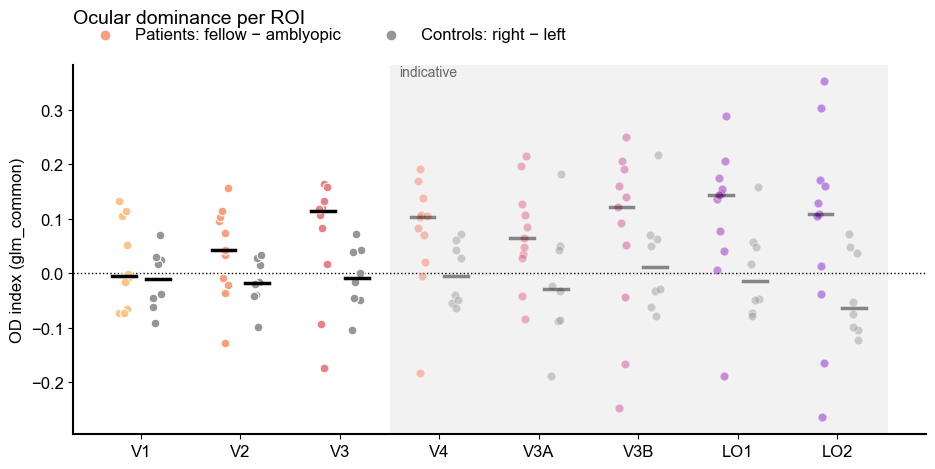

In [9]:
def bh_fdr(p):
    p = np.asarray(p, float)
    o = np.argsort(p)
    q = p[o] * len(p) / (np.arange(len(p)) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty_like(q)
    out[o] = np.minimum(q, 1)
    return out


rows = []
for roi in rois_to_keep:
    vp = od_full[(od_full.group == 'patient') & (od_full.roi == roi)].od.dropna().values
    vc = od_full[(od_full.group == 'control') & (od_full.roi == roi)].od.dropna().values
    pooled_sd = np.sqrt(((vp.size - 1) * vp.var(ddof=1) + (vc.size - 1) * vc.var(ddof=1)) / (vp.size + vc.size - 2))
    rows.append({'roi': roi, 'main': roi in main_rois, 'n_pat': vp.size, 'n_ctrl': vc.size,
                 'median_patients': np.median(vp), 'median_controls': np.median(vc), 'sd_controls': vc.std(ddof=1),
                 'd': (vp.mean() - vc.mean()) / pooled_sd,
                 'p_patients_vs_0': stats.wilcoxon(vp)[1], 'p_patients_vs_controls': stats.mannwhitneyu(vp, vc)[1]})
group_stats = pd.DataFrame(rows)
for col in ['p_patients_vs_0', 'p_patients_vs_controls']:
    group_stats[col + '_fdr'] = np.nan
    for is_main in [True, False]:
        sel = group_stats.main == is_main
        group_stats.loc[sel, col + '_fdr'] = bh_fdr(group_stats.loc[sel, col])
print(group_stats.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 4.8))
rng = np.random.default_rng(0)
for i, roi in enumerate(rois_to_keep):
    alpha = 1 if roi in main_rois else 0.45
    for g, dx, color in [('patient', -0.17, roi_colors[roi]), ('control', 0.17, color_ctrl)]:
        v = od_full[(od_full.group == g) & (od_full.roi == roi)].od.dropna().values
        ax.scatter(i + dx + rng.uniform(-0.05, 0.05, v.size), v, s=40, color=color, alpha=alpha,
                   edgecolor='white', linewidth=0.8, zorder=3)
        ax.plot([i + dx - 0.12, i + dx + 0.12], [np.median(v)] * 2, color='black', lw=2.5, alpha=alpha, zorder=4)
ax.axvspan(len(main_rois) - 0.5, len(rois_to_keep) - 0.5, color='0.95', zorder=0)
ax.text(len(main_rois) - 0.4, ax.get_ylim()[1], 'indicative', va='top', fontsize=10, color='0.4')
ax.axhline(0, color='black', lw=1, ls=':')
ax.set_xticks(range(len(rois_to_keep)))
ax.set_xticklabels(rois_to_keep)
ax.set_ylabel('OD index (glm_common)')
ax.scatter([], [], color=roi_colors['V2'], label='Patients: fellow − amblyopic')
ax.scatter([], [], color=color_ctrl, label='Controls: right − left')
ax.legend(frameon=False, loc='lower left', bbox_to_anchor=(0, 1.02), ncol=2)
ax.set_title('Ocular dominance per ROI', loc='left', fontsize=14, pad=30)
plt.show()

## 2. Run reliability

### 2a. The three 2-vs-2 splits of the 4 runs

The OD index of every subject is computed from runs of half A and of half B (same runs for both eyes), for the three possible splits:

- **Bars | Rings+Wedges** (also a stimulus split),
- **Bars01+Rings | Bars02+Wedges**,
- **Bars01+Wedges | Bars02+Rings**.

For each split: correlation across subjects of the ROI index (are differences between subjects real?) and median vertex-wise correlation within subjects (are the maps reproducible?). Spearman-Brown: r_4runs = 2r / (1 + r), the expected reliability of the 4-run index.

Across subjects, r (half A vs half B):
roi                             V1    V2    V3    V4   V3A   V3B   LO1   LO2
split                                                                       
Bars | Rings+Wedges           0.05  0.32  0.63  0.41  0.83  0.07  0.30  0.53
Bars01+Rings | Bars02+Wedges  0.26  0.37  0.60  0.54  0.24  0.13  0.42  0.64
Bars01+Wedges | Bars02+Rings  0.41  0.68  0.75  0.62  0.41  0.47  0.63  0.57

Spearman-Brown, expected r of the 4-run index:
roi                             V1    V2    V3    V4   V3A   V3B   LO1   LO2
split                                                                       
Bars | Rings+Wedges           0.10  0.49  0.77  0.58  0.90  0.13  0.46  0.69
Bars01+Rings | Bars02+Wedges  0.41  0.54  0.75  0.70  0.38  0.24  0.59  0.78
Bars01+Wedges | Bars02+Rings  0.58  0.81  0.86  0.77  0.58  0.64  0.77  0.72

Vertex-wise r (median across subjects):
roi                             V1    V2    V3    V4   V3A   V3B   LO1   LO2
split                    

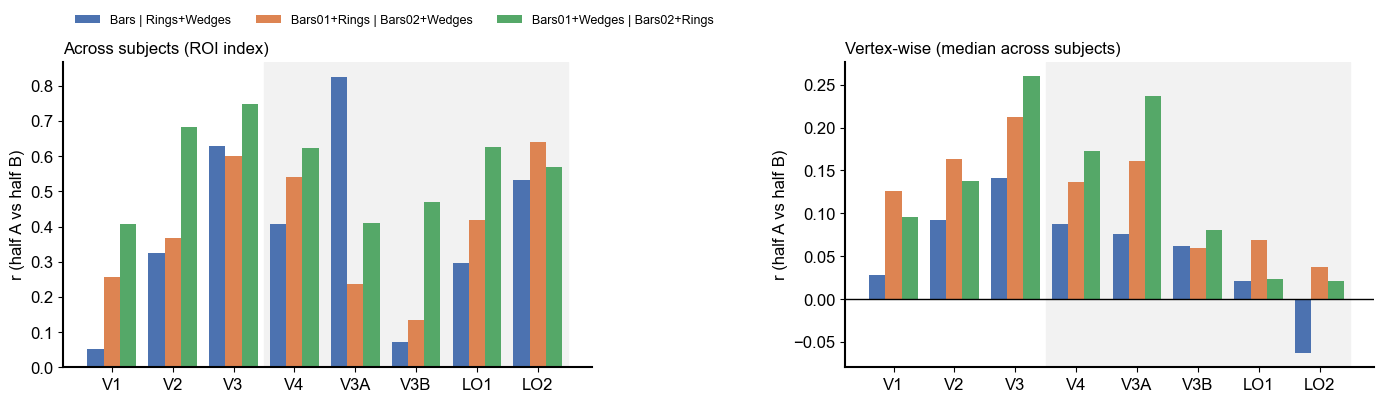

In [10]:
splits = {'Bars | Rings+Wedges': ([0, 1], [2, 3]),
          'Bars01+Rings | Bars02+Wedges': ([0, 2], [1, 3]),
          'Bars01+Wedges | Bars02+Rings': ([0, 3], [1, 2])}

rows_subj, rows_vert = [], []
for split, (runs_A, runs_B) in splits.items():
    half = {}
    for subject in subjects:
        half[subject] = (roi_index(subject, runs_A, runs_A), roi_index(subject, runs_B, runs_B))
        # Vertex-wise
        s = run_sums[subject]
        od_h = []
        for runs in (runs_A, runs_B):
            b_L, _ = glm_from_sums(s, 0, runs)
            b_R, _ = glm_from_sums(s, 1, runs)
            od_h.append(od_ratio(b_L, b_R))
        for roi in rois_to_keep:
            m = keep[subject] & (s['roi'] == roi) & np.isfinite(od_h[0]) & np.isfinite(od_h[1])
            if m.sum() > 10:
                rows_vert.append({'split': split, 'subject': subject, 'roi': roi,
                                  'r_vertex': np.corrcoef(od_h[0][m], od_h[1][m])[0, 1]})
    for roi in rois_to_keep:
        a = np.array([half[s][0][roi] for s in subjects])
        b = np.array([half[s][1][roi] for s in subjects])
        ok = np.isfinite(a) & np.isfinite(b)
        r = np.corrcoef(a[ok], b[ok])[0, 1]
        rows_subj.append({'split': split, 'roi': roi, 'n': ok.sum(), 'r_subjects': r,
                          'r_4runs_SB': 2 * r / (1 + r) if r > 0 else np.nan})
rel_split = pd.DataFrame(rows_subj)
rel_split_vert = pd.DataFrame(rows_vert).groupby(['split', 'roi']).r_vertex.median().reset_index()

print('Across subjects, r (half A vs half B):')
print(rel_split.pivot(index='split', columns='roi', values='r_subjects').reindex(columns=rois_to_keep).round(2))
print('\nSpearman-Brown, expected r of the 4-run index:')
print(rel_split.pivot(index='split', columns='roi', values='r_4runs_SB').reindex(columns=rois_to_keep).round(2))
print('\nVertex-wise r (median across subjects):')
print(rel_split_vert.pivot(index='split', columns='roi', values='r_vertex').reindex(columns=rois_to_keep).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
split_colors = ['#4c72b0', '#dd8452', '#55a868']
width = 0.8 / len(splits)
for ax, table, col, title in [(axes[0], rel_split, 'r_subjects', 'Across subjects (ROI index)'),
                              (axes[1], rel_split_vert, 'r_vertex', 'Vertex-wise (median across subjects)')]:
    for i, split in enumerate(splits):
        t = table[table.split == split].set_index('roi').reindex(rois_to_keep)
        ax.bar(np.arange(len(rois_to_keep)) + (i - 1) * width, t[col], width, color=split_colors[i], label=split)
    ax.axvspan(len(main_rois) - 0.5, len(rois_to_keep) - 0.5, color='0.95', zorder=0)
    ax.axhline(0, color='black', lw=1)
    ax.set_xticks(range(len(rois_to_keep)))
    ax.set_xticklabels(rois_to_keep)
    ax.set_ylabel('r (half A vs half B)')
    ax.set_title(title, loc='left', fontsize=12)
axes[0].legend(frameon=False, fontsize=9, loc='lower left', bbox_to_anchor=(0, 1.08), ncol=3)
plt.tight_layout()
plt.show()

### 2b. Single-run correlations (all run pairs)

The OD index computed from **one run** of each eye (run r of the left eye vs run r of the right eye), for each of the 4 runs. Then the correlation between every pair of runs (6 pairs), across subjects and vertex-wise. The mean single-run r gives, with Spearman-Brown, the expected reliability of the 4-run index: r_4 = 4r / (1 + 3r).

Across subjects, r per run pair:
roi                V1    V2    V3    V4   V3A   V3B   LO1   LO2
pair                                                           
Bars01 - Bars02  0.26  0.35  0.43  0.33  0.17  0.14  0.58  0.64
Bars01 - Rings  -0.07  0.23  0.46  0.42  0.53 -0.08  0.27  0.40
Bars01 - Wedges  0.23  0.14  0.49  0.45  0.32 -0.11  0.05  0.49
Bars02 - Rings  -0.08  0.15  0.47  0.19  0.10 -0.29  0.22  0.33
Bars02 - Wedges  0.36  0.43  0.56  0.41  0.30  0.35  0.23  0.34
Rings - Wedges   0.43  0.59  0.73  0.52 -0.31 -0.06  0.44  0.12

Vertex-wise r per run pair (median across subjects):
roi                V1    V2    V3    V4   V3A   V3B   LO1   LO2
pair                                                           
Bars01 - Bars02  0.14  0.19  0.22  0.14  0.16  0.18  0.11 -0.01
Bars01 - Rings   0.08  0.14  0.18  0.09  0.11  0.00  0.01  0.05
Bars01 - Wedges  0.05  0.12  0.11  0.10  0.11  0.11  0.06  0.00
Bars02 - Rings   0.12  0.12  0.14  0.04  0.06  0.05  0.02 -0.03
Bars02 - Wedges  

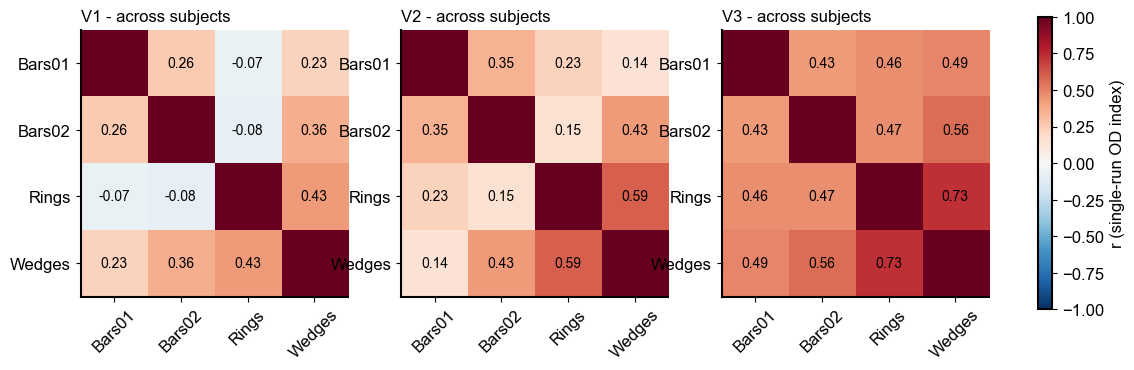

In [11]:
single = {subject: [roi_index(subject, [r], [r]) for r in range(n_runs)] for subject in subjects}
single_od = {}
for subject in subjects:
    s = run_sums[subject]
    single_od[subject] = []
    for r in range(n_runs):
        b_L, _ = glm_from_sums(s, 0, [r])
        b_R, _ = glm_from_sums(s, 1, [r])
        single_od[subject].append(od_ratio(b_L, b_R))

rows = []
for r1, r2 in itertools.combinations(range(n_runs), 2):
    for roi in rois_to_keep:
        a = np.array([single[s][r1][roi] for s in subjects])
        b = np.array([single[s][r2][roi] for s in subjects])
        ok = np.isfinite(a) & np.isfinite(b)
        r_v = []
        for subject in subjects:
            m = keep[subject] & (run_sums[subject]['roi'] == roi)
            va, vb = single_od[subject][r1][m], single_od[subject][r2][m]
            okv = np.isfinite(va) & np.isfinite(vb)
            if okv.sum() > 10:
                r_v.append(np.corrcoef(va[okv], vb[okv])[0, 1])
        rows.append({'pair': '{} - {}'.format(run_names[r1], run_names[r2]), 'roi': roi,
                     'r_subjects': np.corrcoef(a[ok], b[ok])[0, 1], 'r_vertex': np.median(r_v)})
run_pairs = pd.DataFrame(rows)
print('Across subjects, r per run pair:')
print(run_pairs.pivot(index='pair', columns='roi', values='r_subjects').reindex(columns=rois_to_keep).round(2))
print('\nVertex-wise r per run pair (median across subjects):')
print(run_pairs.pivot(index='pair', columns='roi', values='r_vertex').reindex(columns=rois_to_keep).round(2))

mean_r = run_pairs.groupby('roi')[['r_subjects', 'r_vertex']].mean().reindex(rois_to_keep)
mean_r['r_subjects_4runs_SB'] = 4 * mean_r.r_subjects / (1 + 3 * mean_r.r_subjects)
mean_r['r_vertex_4runs_SB'] = 4 * mean_r.r_vertex / (1 + 3 * mean_r.r_vertex)
print('\nMean single-run r and Spearman-Brown prediction for 4 runs:')
print(mean_r.round(2))

# Matrix of the across-subject correlations for the main ROIs
fig, axes = plt.subplots(1, len(main_rois), figsize=(4.2 * len(main_rois), 3.8))
for ax, roi in zip(axes, main_rois):
    mat = np.eye(n_runs)
    for r1, r2 in itertools.combinations(range(n_runs), 2):
        v = run_pairs[(run_pairs.roi == roi) & (run_pairs.pair == '{} - {}'.format(run_names[r1], run_names[r2]))].r_subjects.iloc[0]
        mat[r1, r2] = mat[r2, r1] = v
    im = ax.imshow(mat, cmap='RdBu_r', vmin=-1, vmax=1)
    for r1 in range(n_runs):
        for r2 in range(n_runs):
            if r1 != r2:
                ax.text(r2, r1, '{:.2f}'.format(mat[r1, r2]), ha='center', va='center', fontsize=10)
    ax.set_xticks(range(n_runs))
    ax.set_xticklabels(run_names, rotation=45)
    ax.set_yticks(range(n_runs))
    ax.set_yticklabels(run_names)
    ax.set_title('{} - across subjects'.format(roi), loc='left', fontsize=12)
fig.colorbar(im, ax=axes, fraction=0.02, label='r (single-run OD index)')
plt.show()

## 3. Within-eye noise floor

The same index computed between two halves of the **same eye** (Bars01+Rings vs Bars02+Wedges), i.e. a "dominance" with no real dominance: its spread is what run-to-run changes (attention, fixation, gain) produce on their own. Compared with the between-eye index computed from the same amount of data (mean of the two halves). Grey band: central 95 % of the within-eye values.

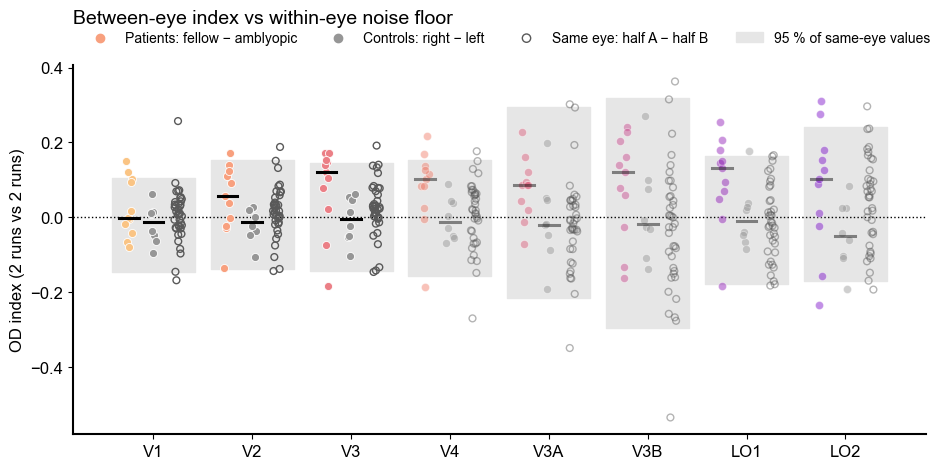

roi  within_sd  band_lo  band_hi  between_sd_controls  patients_above_band_%  controls_outside_band_%
 V1      0.070   -0.148    0.103                0.051                 18.182                      0.0
 V2      0.068   -0.139    0.153                0.046                  9.091                      0.0
 V3      0.072   -0.143    0.144                0.060                 36.364                      0.0
 V4      0.088   -0.159    0.152                0.056                 18.182                      0.0
V3A      0.120   -0.217    0.294                0.114                  0.000                      0.0
V3B      0.169   -0.297    0.318                0.131                  0.000                      0.0
LO1      0.097   -0.180    0.162                0.084                 27.273                     12.5
LO2      0.120   -0.172    0.241                0.089                 18.182                     12.5


In [12]:
runs_A, runs_B = splits['Bars01+Rings | Bars02+Wedges']
rows = []
for subject in subjects:
    s = run_sums[subject]
    between = {roi: np.mean([roi_index(subject, runs_A, runs_A)[roi], roi_index(subject, runs_B, runs_B)[roi]])
               for roi in rois_to_keep}
    within = {}
    for i, e in enumerate(eyes):
        b_A, _ = glm_from_sums(s, i, runs_A)
        b_B, _ = glm_from_sums(s, i, runs_B)
        within[e] = od_ratio(b_A, b_B)
    for roi in rois_to_keep:
        m = keep[subject] & (s['roi'] == roi)
        rows.append({'subject': subject, 'group': 'patient' if subject in patients else 'control', 'roi': roi,
                     'between': between[roi],
                     'within_L': np.nanmedian(within['L'][m]), 'within_R': np.nanmedian(within['R'][m])})
floor = pd.DataFrame(rows)

rows = []
fig, ax = plt.subplots(figsize=(11, 4.8))
rng = np.random.default_rng(1)
for i, roi in enumerate(rois_to_keep):
    alpha = 1 if roi in main_rois else 0.45
    d = floor[floor.roi == roi]
    pv = np.concatenate([d.within_L.dropna(), d.within_R.dropna()])
    lo, hi = np.percentile(pv, [2.5, 97.5])
    ax.fill_between([i - 0.42, i + 0.42], lo, hi, color='0.9', zorder=0)
    for g, dx, color in [('patient', -0.25, roi_colors[roi]), ('control', 0, color_ctrl)]:
        v = d[d.group == g].between.dropna().values
        ax.scatter(i + dx + rng.uniform(-0.04, 0.04, v.size), v, s=34, color=color, alpha=alpha,
                   edgecolor='white', linewidth=0.6, zorder=3)
        ax.plot([i + dx - 0.1, i + dx + 0.1], [np.median(v)] * 2, color='black', lw=2.2, alpha=alpha, zorder=4)
    ax.scatter(i + 0.25 + rng.uniform(-0.04, 0.04, pv.size), pv, s=24, facecolor='none', edgecolor='0.35',
               alpha=alpha, linewidth=1, zorder=3)
    vp = d[d.group == 'patient'].between.dropna().values
    vc = d[d.group == 'control'].between.dropna().values
    rows.append({'roi': roi, 'within_sd': pv.std(), 'band_lo': lo, 'band_hi': hi,
                 'between_sd_controls': vc.std(ddof=1), 'patients_above_band_%': 100 * np.mean(vp > hi),
                 'controls_outside_band_%': 100 * np.mean((vc > hi) | (vc < lo))})
ax.axhline(0, color='black', lw=1, ls=':')
ax.set_xticks(range(len(rois_to_keep)))
ax.set_xticklabels(rois_to_keep)
ax.set_ylabel('OD index (2 runs vs 2 runs)')
ax.scatter([], [], color=roi_colors['V2'], label='Patients: fellow − amblyopic')
ax.scatter([], [], color=color_ctrl, label='Controls: right − left')
ax.scatter([], [], facecolor='none', edgecolor='0.35', label='Same eye: half A − half B')
ax.fill_between([], [], [], color='0.9', label='95 % of same-eye values')
ax.legend(frameon=False, loc='lower left', bbox_to_anchor=(0, 1.02), ncol=4, fontsize=10)
ax.set_title('Between-eye index vs within-eye noise floor', loc='left', fontsize=14, pad=30)
plt.show()
noise_floor = pd.DataFrame(rows)
print(noise_floor.round(3).to_string(index=False))

## 4. Per-subject permutation of the eye labels

For each subject, the 8 runs (4 per eye) are split in all 70 ways into a pseudo "left eye" and a pseudo "right eye" group of 4 runs, giving a subject-specific null distribution of the index. p = fraction of splits with |index| ≥ |real index| (the real split and its mirror always count: smallest p = 2/70 ≈ 0.029). Possible because, with the common regressor, the regressor of run r is the same for both eyes.

              n  p<0.05  p<0.05 & positive
roi group                                 
V1  control   8       0                  0
    patient  11       0                  0
V2  control   8       0                  0
    patient  11       0                  0
V3  control   8       0                  0
    patient  11       3                  3
V4  control   8       0                  0
    patient  11       1                  1
V3A control   8       2                  1
    patient  11       1                  1
V3B control   8       0                  0
    patient  11       1                  1
LO1 control   8       0                  0
    patient  11       1                  1
LO2 control   8       0                  0
    patient  11       0                  0


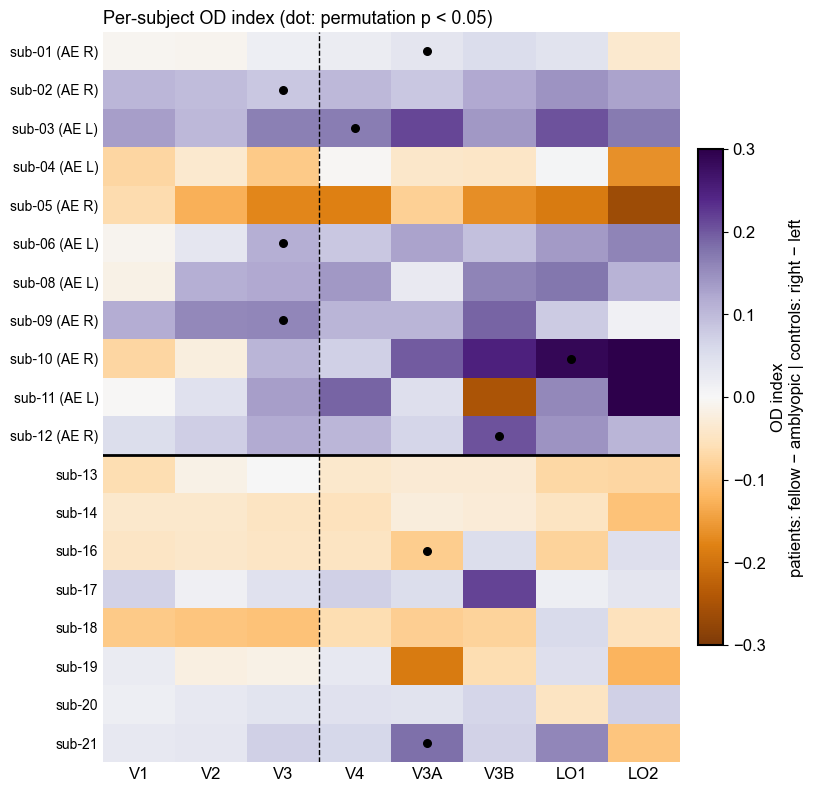

In [13]:
run_ids = [(0, r) for r in range(n_runs)] + [(1, r) for r in range(n_runs)]       # (eye, run)
combos = list(itertools.combinations(range(len(run_ids)), n_runs))
true_combo = tuple(range(n_runs))

rows = []
for subject in subjects:
    s = run_sums[subject]
    # β of a group of (eye, run) items, from the sums
    null = {roi: [] for roi in rois_to_keep}
    for c in combos:
        other = [i for i in range(len(run_ids)) if i not in c]
        betas = []
        for group in (c, other):
            sxy = sum(s['sxy_common'][run_ids[i][0], run_ids[i][1]] for i in group)
            sxx = sum(s['sxx_common'][run_ids[i][1]] for i in group)
            with np.errstate(divide='ignore', invalid='ignore'):
                betas.append(sxy / sxx)
        od = od_ratio(betas[0], betas[1])
        for roi in rois_to_keep:
            null[roi].append(sign[subject] * np.nanmedian(od[keep[subject] & (s['roi'] == roi)]))
    i_true = combos.index(true_combo)
    for roi in rois_to_keep:
        v = np.array(null[roi])
        rows.append({'subject': subject, 'group': 'patient' if subject in patients else 'control', 'roi': roi,
                     'od': v[i_true], 'p_perm': np.mean(np.abs(v) >= np.abs(v[i_true]) - 1e-12)})
perm = pd.DataFrame(rows)

summary = perm.assign(sig=perm.p_perm < 0.05, pos=perm.od > 0).groupby(['roi', 'group']).apply(
    lambda d: pd.Series({'n': len(d), 'p<0.05': int(d.sig.sum()), 'p<0.05 & positive': int((d.sig & d.pos).sum())}))
print(summary.reindex(rois_to_keep, level=0))

subj_order = [s for s in patients + controls if s in subjects]
mat = perm.pivot(index='subject', columns='roi', values='od').reindex(index=subj_order, columns=rois_to_keep)
pmat = perm.pivot(index='subject', columns='roi', values='p_perm').reindex(index=subj_order, columns=rois_to_keep)
fig, ax = plt.subplots(figsize=(8, 0.42 * len(subj_order) + 1.5))
im = ax.imshow(mat.values, cmap='PuOr', vmin=-0.3, vmax=0.3, aspect='auto')
yy, xx = np.where(pmat.values < 0.05)
ax.scatter(xx, yy, s=30, color='black', zorder=3)
n_pat = sum(s in patients for s in subj_order)
ax.axhline(n_pat - 0.5, color='black', lw=2)
ax.axvline(len(main_rois) - 0.5, color='black', lw=1, ls='--')
ax.set_xticks(range(len(rois_to_keep)))
ax.set_xticklabels(rois_to_keep)
ax.set_yticks(range(len(subj_order)))
ax.set_yticklabels(['{} (AE {})'.format(s, ambly_eye[s]) if s in ambly_eye else s for s in subj_order], fontsize=10)
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03, label='OD index\npatients: fellow − amblyopic | controls: right − left')
ax.set_title('Per-subject OD index (dot: permutation p < 0.05)', loc='left', fontsize=13)
plt.show()

## 5. Relation with amblyopia depth

Patients only (n = 12): Spearman correlation between the fellow − amblyopic index and (1) the logMAR of the amblyopic eye, (2) the interocular difference (logMAR amblyopic − logMAR fellow, when available). Shown for the 4-run index and, as a check, for each half of the interleaved split (a real relation should be seen in both).

roi  rho_logMAR_4runs  p_logMAR  rho_logMAR_half_A  rho_logMAR_half_B  rho_delta_logMAR_4runs  p_delta_logMAR  rho_delta_logMAR_half_A  rho_delta_logMAR_half_B
 V1              0.17      0.62               0.42              -0.12                    0.10            0.79                     0.42                    -0.24
 V2              0.49      0.13               0.51               0.12                    0.52            0.13                     0.52                     0.10
 V3              0.29      0.39               0.50              -0.03                    0.28            0.44                     0.48                    -0.06
 V4              0.31      0.36               0.20               0.21                    0.29            0.42                     0.18                     0.17
V3A             -0.05      0.87              -0.14              -0.00                   -0.09            0.81                    -0.18                    -0.02
V3B              0.25      0.46         

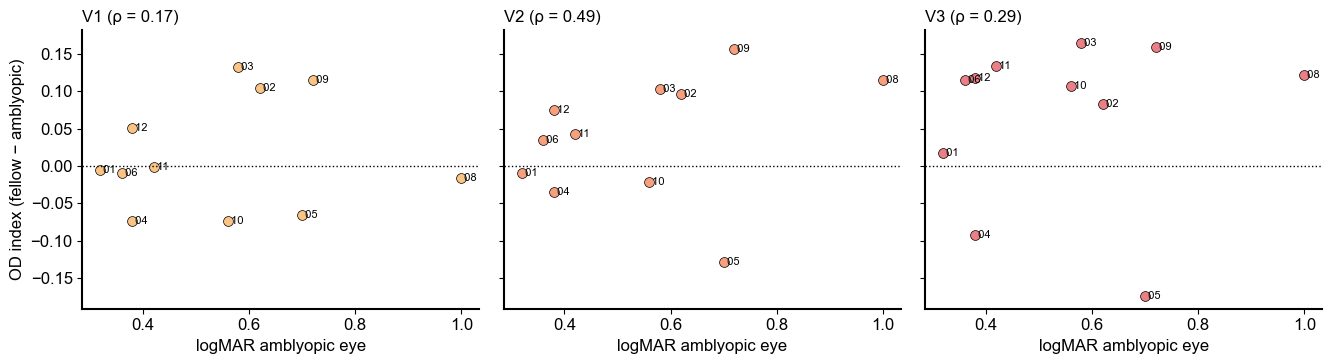

In [14]:
rows = []
halves_idx = {s: (roi_index(s, runs_A, runs_A), roi_index(s, runs_B, runs_B)) for s in subjects if s in patients}
pat = [s for s in subjects if s in patients]
acuity = np.array([log_mar[s] for s in pat])
delta = np.array([log_mar[s] - log_mar_fellow[s] for s in pat])
for roi in rois_to_keep:
    v_full = od_full[(od_full.roi == roi)].set_index('subject').od.reindex(pat).values
    v_A = np.array([halves_idx[s][0][roi] for s in pat])
    v_B = np.array([halves_idx[s][1][roi] for s in pat])
    row = {'roi': roi}
    for name, clin in [('logMAR', acuity), ('delta_logMAR', delta)]:
        for part, v in [('4runs', v_full), ('half_A', v_A), ('half_B', v_B)]:
            ok = np.isfinite(v) & np.isfinite(clin)
            rho, p = stats.spearmanr(v[ok], clin[ok])
            row['rho_{}_{}'.format(name, part)] = rho
            if part == '4runs':
                row['p_{}'.format(name)] = p
    rows.append(row)
clinical = pd.DataFrame(rows)
print(clinical.round(2).to_string(index=False))

fig, axes = plt.subplots(1, len(main_rois), figsize=(4.5 * len(main_rois), 3.8), sharey=True)
for ax, roi in zip(axes, main_rois):
    v = od_full[(od_full.roi == roi)].set_index('subject').od.reindex(pat).values
    ax.scatter(acuity, v, s=50, color=roi_colors[roi], edgecolor='black', linewidth=0.5)
    for s, a, val in zip(pat, acuity, v):
        ax.text(a, val, ' ' + s[4:], fontsize=8, va='center')
    ax.axhline(0, color='black', lw=1, ls=':')
    ax.set_xlabel('logMAR amblyopic eye')
    ax.set_title('{} (ρ = {:.2f})'.format(roi, stats.spearmanr(acuity, v, nan_policy='omit')[0]), loc='left', fontsize=12)
axes[0].set_ylabel('OD index (fellow − amblyopic)')
plt.tight_layout()
plt.show()

## 6. Supplementary: own regressor (`glm_own`)

Same index with each eye's own prediction as regressor. If the result is the same, the choice of the common regressor does not drive the effect.

In [15]:
rows = []
for subject in subjects:
    own = roi_index(subject, all_runs, all_runs, regressor='own')
    for roi in rois_to_keep:
        rows.append({'subject': subject, 'group': 'patient' if subject in patients else 'control', 'roi': roi, 'od_own': own[roi]})
od_own = pd.DataFrame(rows).merge(od_full, on=['subject', 'group', 'roi'])

rows = []
for roi in rois_to_keep:
    d = od_own[od_own.roi == roi].dropna()
    vp, vc = d[d.group == 'patient'].od_own.values, d[d.group == 'control'].od_own.values
    rows.append({'roi': roi, 'r_common_own': np.corrcoef(d.od, d.od_own)[0, 1],
                 'median_patients_own': np.median(vp), 'median_controls_own': np.median(vc),
                 'p_patients_vs_controls_own': stats.mannwhitneyu(vp, vc)[1]})
print(pd.DataFrame(rows).round(3).to_string(index=False))

roi  r_common_own  median_patients_own  median_controls_own  p_patients_vs_controls_own
 V1         0.969               -0.001               -0.006                       0.657
 V2         0.986                0.042               -0.012                       0.109
 V3         0.996                0.116               -0.011                       0.033
 V4         0.991                0.107                0.004                       0.026
V3A         0.995                0.056               -0.028                       0.075
V3B         0.978                0.131                0.030                       0.442
LO1         0.975                0.140               -0.013                       0.026
LO2         0.991                0.137               -0.058                       0.062


## Summary

Main ROIs (V1, V2, V3) first. Read with the markdown below.

In [16]:
summary = group_stats.set_index('roi')[['median_patients', 'median_controls', 'd', 'p_patients_vs_controls_fdr']].copy()
summary['r_split_interleaved'] = rel_split[rel_split.split == 'Bars01+Rings | Bars02+Wedges'].set_index('roi').r_subjects
summary['r_split_stimulus'] = rel_split[rel_split.split == 'Bars | Rings+Wedges'].set_index('roi').r_subjects
summary['r_4runs_SB_single'] = mean_r.r_subjects_4runs_SB
summary['r_vertex_4runs_SB'] = mean_r.r_vertex_4runs_SB
summary['within_eye_sd'] = noise_floor.set_index('roi').within_sd
summary['n_patients_perm_sig'] = perm[(perm.group == 'patient') & (perm.p_perm < 0.05) & (perm.od > 0)].groupby('roi').size()
summary['n_controls_perm_sig'] = perm[(perm.group == 'control') & (perm.p_perm < 0.05)].groupby('roi').size()
summary['rho_logMAR'] = clinical.set_index('roi').rho_logMAR_4runs
summary = summary.reindex(rois_to_keep).fillna({'n_patients_perm_sig': 0, 'n_controls_perm_sig': 0})
print(summary.round(3).to_string())

     median_patients  median_controls      d  p_patients_vs_controls_fdr  r_split_interleaved  r_split_stimulus  r_4runs_SB_single  r_vertex_4runs_SB  within_eye_sd  n_patients_perm_sig  n_controls_perm_sig  rho_logMAR
roi                                                                                                                                                                                                                       
V1            -0.005           -0.010  0.385                       0.657                0.256             0.051              0.484              0.314          0.070                  0.0                  0.0       0.169
V2             0.042           -0.018  0.809                       0.093                0.366             0.324              0.649              0.398          0.068                  0.0                  0.0       0.487
V3             0.114           -0.008  0.831                       0.093                0.599             0.629             

### How to read it

- **Group effect** (`d`, `p_patients_vs_controls_fdr`): is the fellow eye more represented in patients than one eye vs the other in controls?
- **Reliability** (`r_split_*`, `r_4runs_SB_*`): above ~0.5 the subject values can be compared between subjects (ranking, correlation with clinical data); below, only the group level is interpretable. `r_split_stimulus` is usually lower than `r_split_interleaved` because the two halves also differ in stimulus.
- **Noise floor** (`within_eye_sd`): if it is of the same order as the patients' median, single-subject values cannot be distinguished from run-to-run changes; the group effect can still be real because this noise has no preferred sign.
- **Permutation**: number of individual patients whose own eye split is the most extreme; controls give the false-positive rate (≈ 1/35 per ROI by chance).
- **logMAR**: only meaningful if the reliability is sufficient, and if the sign is the same in both halves.
- Caveat for all measures: the two eyes are recorded in different runs, so a global gain difference between the runs of each eye adds to the index; the control spread and the within-eye noise floor are the estimates of that noise.

## 7. Which ROI summary: median OD, weighted OD or z?

Four ways to summarise the vertices of a ROI into one value per subject (same vertices, same β):

| variant | value per ROI | idea |
|---|---|---|
| `median` | median of the OD index | current choice, robust to extreme vertices |
| `r2_weighted` | mean of the OD index weighted by the pRF R² (mean of both eyes) | more weight to well-fitted vertices |
| `ivar_weighted` | mean of the OD index weighted by 1 / variance of the index (from the SE of β_L and β_R) | statistically optimal weighting |
| `median_z` | median of z = (β_L − β_R) / √(SE_L² + SE_R²) | reliability of the difference instead of its size |

Expected problem of the weighted versions: a vertex where the amblyopic eye responds weakly has a lower amblyopic R² (and a less precise index), so it gets less weight although it is strongly dominated by the fellow eye → the weighted index could be pulled toward 0.

Compared on: the group effect (patients vs controls, d and uncorrected p) and the split-half reliability across subjects (mean of the two interleaved splits, which do not mix stimulus and half). The best variant is the most reliable one at similar group separation; if all agree, the simplest (`median`) is enough.

Median patients / controls:
roi               V1     V2     V3     V4    V3A    V3B    LO1    LO2
variant                                                              
median        -0.005  0.042  0.114  0.103  0.064  0.121  0.144  0.109
r2_weighted    0.008  0.078  0.125  0.095  0.105  0.115  0.139  0.085
ivar_weighted  0.020  0.075  0.132  0.106  0.101  0.106  0.142  0.114
median_z      -0.074  0.355  0.949  0.943  0.873  1.409  0.909  0.607
roi               V1     V2     V3     V4    V3A    V3B    LO1    LO2
variant                                                              
median        -0.010 -0.018 -0.008 -0.005 -0.028  0.011 -0.015 -0.063
r2_weighted   -0.005 -0.011 -0.005 -0.019 -0.009  0.002 -0.001 -0.044
ivar_weighted -0.009 -0.016 -0.005 -0.026 -0.006 -0.001  0.004 -0.044
median_z      -0.106 -0.147 -0.053 -0.147 -0.387  0.003 -0.135 -0.719

d (patients vs controls):
roi              V1    V2    V3    V4   V3A   V3B   LO1   LO2
variant                                    

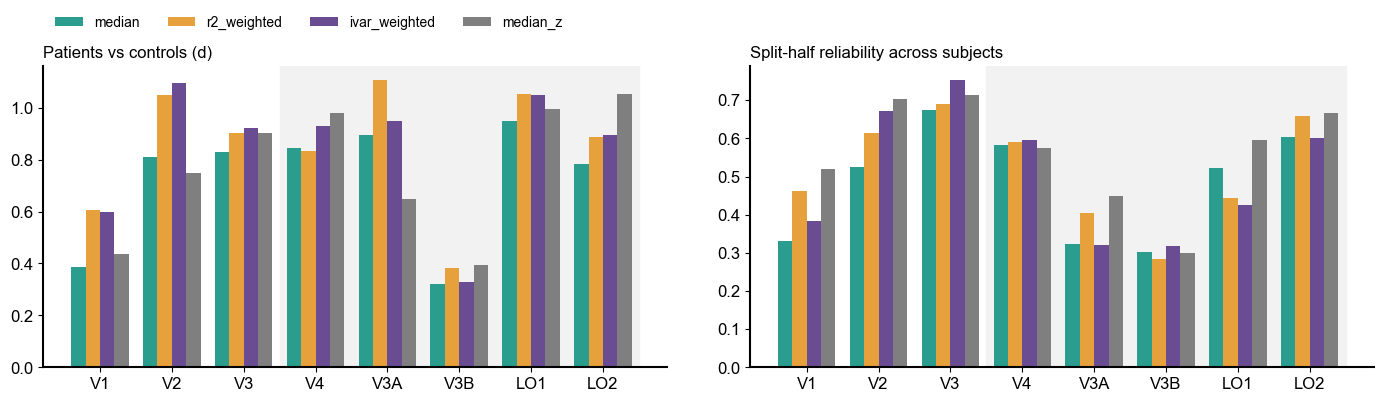

In [17]:
variants = ['median', 'r2_weighted', 'ivar_weighted', 'median_z']


def roi_variants(subject, runs):
    """Signed ROI values of the four variants, from the given runs (same runs for both eyes)."""
    s = run_sums[subject]
    b_L, se_L = glm_from_sums(s, 0, runs)
    b_R, se_R = glm_from_sums(s, 1, runs)
    od = od_ratio(b_L, b_R)
    with np.errstate(divide='ignore', invalid='ignore'):
        z = (b_L - b_R) / np.sqrt(se_L ** 2 + se_R ** 2)
        var_od = 4 * (b_R ** 2 * se_L ** 2 + b_L ** 2 * se_R ** 2) / (b_L + b_R) ** 4
    r2 = np.clip(np.nanmean([s['fit_L'][fit_maps.index('r_squared')], s['fit_R'][fit_maps.index('r_squared')]], axis=0), 0, None)
    out = {v: {} for v in variants}
    for roi in rois_to_keep:
        m = keep[subject] & (s['roi'] == roi) & np.isfinite(od) & np.isfinite(var_od) & (var_od > 0)
        out['median'][roi] = sign[subject] * np.median(od[m])
        out['r2_weighted'][roi] = sign[subject] * np.sum(r2[m] * od[m]) / np.sum(r2[m])
        out['ivar_weighted'][roi] = sign[subject] * np.sum(od[m] / var_od[m]) / np.sum(1 / var_od[m])
        out['median_z'][roi] = sign[subject] * np.median(z[m])
    return out


# All runs, and the two interleaved splits
parts = {'full': (all_runs, all_runs)}
for split in ['Bars01+Rings | Bars02+Wedges', 'Bars01+Wedges | Bars02+Rings']:
    parts[split + ' A'] = (splits[split][0],)
    parts[split + ' B'] = (splits[split][1],)
rows = []
for subject in subjects:
    for part, runs in parts.items():
        vals = roi_variants(subject, runs[0])
        for v in variants:
            for roi in rois_to_keep:
                rows.append({'subject': subject, 'group': 'patient' if subject in patients else 'control',
                             'part': part, 'variant': v, 'roi': roi, 'value': vals[v][roi]})
variant_values = pd.DataFrame(rows)

# Group effect (all runs)
rows = []
for v in variants:
    for roi in rois_to_keep:
        d = variant_values[(variant_values.part == 'full') & (variant_values.variant == v) & (variant_values.roi == roi)]
        vp, vc = d[d.group == 'patient'].value.dropna().values, d[d.group == 'control'].value.dropna().values
        pooled_sd = np.sqrt(((vp.size - 1) * vp.var(ddof=1) + (vc.size - 1) * vc.var(ddof=1)) / (vp.size + vc.size - 2))
        rows.append({'variant': v, 'roi': roi, 'median_patients': np.median(vp), 'median_controls': np.median(vc),
                     'd': (vp.mean() - vc.mean()) / pooled_sd, 'p_patients_vs_controls': stats.mannwhitneyu(vp, vc)[1]})
variant_group = pd.DataFrame(rows)

# Split-half reliability across subjects (mean of the two interleaved splits)
rows = []
for v in variants:
    for roi in rois_to_keep:
        rs = []
        for split in ['Bars01+Rings | Bars02+Wedges', 'Bars01+Wedges | Bars02+Rings']:
            d = variant_values[(variant_values.variant == v) & (variant_values.roi == roi)]
            a = d[d.part == split + ' A'].set_index('subject').value
            b = d[d.part == split + ' B'].set_index('subject').value.reindex(a.index)
            ok = np.isfinite(a) & np.isfinite(b)
            rs.append(np.corrcoef(a[ok], b[ok])[0, 1])
        rows.append({'variant': v, 'roi': roi, 'r_split': np.mean(rs)})
variant_rel = pd.DataFrame(rows)

print('Median patients / controls:')
print(variant_group.pivot(index='variant', columns='roi', values='median_patients').reindex(index=variants, columns=rois_to_keep).round(3))
print(variant_group.pivot(index='variant', columns='roi', values='median_controls').reindex(index=variants, columns=rois_to_keep).round(3))
print('\nd (patients vs controls):')
print(variant_group.pivot(index='variant', columns='roi', values='d').reindex(index=variants, columns=rois_to_keep).round(2))
print('\np patients vs controls (uncorrected):')
print(variant_group.pivot(index='variant', columns='roi', values='p_patients_vs_controls').reindex(index=variants, columns=rois_to_keep).round(3))
print('\nSplit-half reliability across subjects (mean of the two interleaved splits):')
print(variant_rel.pivot(index='variant', columns='roi', values='r_split').reindex(index=variants, columns=rois_to_keep).round(2))

# Agreement with the median, across subjects (all runs)
rows = []
for v in variants[1:]:
    for roi in rois_to_keep:
        d = variant_values[(variant_values.part == 'full') & (variant_values.roi == roi)]
        a = d[d.variant == 'median'].set_index('subject').value
        b = d[d.variant == v].set_index('subject').value.reindex(a.index)
        rows.append({'variant': v, 'roi': roi, 'r_with_median': np.corrcoef(a, b)[0, 1]})
print('\nCorrelation with the median version across subjects:')
print(pd.DataFrame(rows).pivot(index='variant', columns='roi', values='r_with_median').reindex(index=variants[1:], columns=rois_to_keep).round(2))

# Figure: d and reliability, main ROIs highlighted
variant_colors = {'median': '#2a9d8f', 'r2_weighted': '#e6a03c', 'ivar_weighted': '#6a4c93', 'median_z': '#7f7f7f'}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
width = 0.8 / len(variants)
for ax, table, col, title in [(axes[0], variant_group, 'd', 'Patients vs controls (d)'),
                              (axes[1], variant_rel, 'r_split', 'Split-half reliability across subjects')]:
    for i, v in enumerate(variants):
        t = table[table.variant == v].set_index('roi').reindex(rois_to_keep)
        ax.bar(np.arange(len(rois_to_keep)) + (i - 1.5) * width, t[col], width, color=variant_colors[v], label=v)
    ax.axvspan(len(main_rois) - 0.5, len(rois_to_keep) - 0.5, color='0.95', zorder=0)
    ax.axhline(0, color='black', lw=1)
    ax.set_xticks(range(len(rois_to_keep)))
    ax.set_xticklabels(rois_to_keep)
    ax.set_title(title, loc='left', fontsize=12)
axes[0].legend(frameon=False, fontsize=10, ncol=4, loc='lower left', bbox_to_anchor=(0, 1.08))
plt.tight_layout()
plt.show()

## 8. Flatmaps

One patch per subject, centred between the two hemispheres on the bounding box of both V1s, **red = left eye stronger, blue = right eye stronger** (colour bar left = left eye), transparency = mean pRF R² of both eyes, only the vertices kept by the prf_analysis filters.

Two versions:

- **OD index** (main, same measure as the ROI analysis): colour = (β_L − β_R) / (β_L + β_R), fixed scale ±`od_max`.
- **z** (supplementary): colour = (β_L − β_R) / √(SE_L² + SE_R²), scale ±`zmax` - shows where the difference is reliable rather than how large it is.

Saved in `/Users/uriel/Desktop/fig_od/glm_common/` (patches in `flatmaps/`, group panels and colour bars as png + pdf).

In [18]:
import cortex
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable

# Settings
map_dir = '/Users/uriel/Desktop/fig_od/glm_common'
flatmap_dir = '{}/flatmaps'.format(map_dir)
for d in [map_dir, flatmap_dir]:
    os.makedirs(d, exist_ok=True)
od_max = 0.3                               # colour range of the OD index
zmax = 3                                   # colour range of z
cmap_od = plt.get_cmap('coolwarm_r')       # applied to -value: left end = red = left eye, right end = blue = right eye
alpha_range = analysis_info["flatmap_alpha_range"]
zoom_margin = 0.15                         # margin around the V1 bounding box (fraction of its size)
patch_width_inch = 5
rois_method_format = 'rois-group-mmp'
map_types = {'od': {'vmax': od_max, 'label': '← left eye stronger    OD index    right eye stronger →'},
             'z': {'vmax': zmax, 'label': '← left eye stronger    |z|    right eye stronger →'}}

# Full-surface OD, z and R² maps of every subject (vertices outside the ROIs or not kept: NaN)
od_maps = {}
for subject in subjects:
    s = run_sums[subject]
    b_L, se_L = glm_from_sums(s, 0, all_runs)
    b_R, se_R = glm_from_sums(s, 1, all_runs)
    od = od_ratio(b_L, b_R)
    with np.errstate(divide='ignore', invalid='ignore'):
        z = (b_L - b_R) / np.sqrt(se_L ** 2 + se_R ** 2)
    rsq = np.nanmean([s['fit_L'][fit_maps.index('r_squared')], s['fit_R'][fit_maps.index('r_squared')]], axis=0)

    (lpts, _), (rpts, _) = cortex.db.get_surf(subject, 'flat', nudge=True)
    n_vert_L, n_vert = lpts.shape[0], lpts.shape[0] + rpts.shape[0]
    res = {'n_vert_L': n_vert_L, 'v1': s['vertex'][s['roi'] == 'V1'], 'lpts': lpts, 'rpts': rpts,
           'rsq': np.zeros(n_vert)}
    res['rsq'][s['vertex']] = np.nan_to_num(rsq)
    for name, values in [('od', od), ('z', z)]:
        res[name] = np.full(n_vert, np.nan)
        res[name][s['vertex'][keep[subject]]] = values[keep[subject]]
    od_maps[subject] = res
    print('{}: {} coloured vertices | V1 median OD = {:+.3f}, median z = {:+.2f}'.format(
        subject, np.isfinite(res['od']).sum(), np.nanmedian(res['od'][res['v1']]), np.nanmedian(res['z'][res['v1']])))

sub-01: 24728 coloured vertices | V1 median OD = -0.005, median z = -0.08
sub-02: 19305 coloured vertices | V1 median OD = +0.104, median z = +1.08
sub-03: 21593 coloured vertices | V1 median OD = -0.132, median z = -0.90
sub-04: 13200 coloured vertices | V1 median OD = +0.073, median z = +0.33
sub-05: 21764 coloured vertices | V1 median OD = -0.066, median z = -0.79
sub-06: 28437 coloured vertices | V1 median OD = +0.009, median z = +0.12
sub-08: 24085 coloured vertices | V1 median OD = +0.016, median z = +0.12
sub-09: 21413 coloured vertices | V1 median OD = +0.115, median z = +0.93
sub-10: 17061 coloured vertices | V1 median OD = -0.073, median z = -0.35
sub-11: 15777 coloured vertices | V1 median OD = +0.002, median z = -0.01
sub-12: 16523 coloured vertices | V1 median OD = +0.051, median z = +0.26
sub-13: 21500 coloured vertices | V1 median OD = +0.061, median z = +0.53
sub-14: 24414 coloured vertices | V1 median OD = +0.038, median z = +0.57
sub-16: 26434 coloured vertices | V1 m

In [19]:
def vertex_rgb(subject, values, rsq, vmax):
    """Pycortex VertexRGB: red = left eye, blue = right eye, alpha = pRF R²."""
    norm = mcolors.Normalize(vmin=-vmax, vmax=vmax)
    rgb = cmap_od(norm(np.nan_to_num(-values)))[:, :3] * 255          # -value with coolwarm_r -> left eye red
    alpha = np.clip((rsq - alpha_range[0]) / (alpha_range[1] - alpha_range[0]), 0, 1)
    alpha[~np.isfinite(values)] = 0
    alpha = (alpha * 255).astype(np.uint8)
    return cortex.VertexRGB(red=rgb[:, 0].astype(np.uint8), green=rgb[:, 1].astype(np.uint8),
                            blue=rgb[:, 2].astype(np.uint8), subject=subject, alpha=alpha).blend_curvature(alpha)


def v1_bounds(res):
    """Flatmap box containing left and right V1 (+ margin), centred between the hemispheres."""
    v1, n_vert_L = res['v1'], res['n_vert_L']
    pts = np.vstack([res['lpts'][v1[v1 < n_vert_L], :2], res['rpts'][v1[v1 >= n_vert_L] - n_vert_L, :2]])
    (xmin, ymin), (xmax, ymax) = pts.min(0), pts.max(0)
    mx, my = (xmax - xmin) * zoom_margin / 2, (ymax - ymin) * zoom_margin / 2
    return xmin - mx, xmax + mx, ymin - my, ymax + my


patch_fns = {map_type: {} for map_type in map_types}
for subject in subjects:
    res = od_maps[subject]
    xmin, xmax, ymin, ymax = v1_bounds(res)
    overlay_fn = '{}/db/{}/overlays_{}.svg'.format(cortex_dir, subject, rois_method_format)
    for map_type, prm in map_types.items():
        try:
            fig = cortex.quickshow(vertex_rgb(subject, res[map_type], res['rsq'], prm['vmax']),
                                   depth=1, thick=1, sampler='nearest', with_curvature=True,
                                   nanmean=True, with_labels=False, with_colorbar=False, with_borders=True,
                                   curvature_brightness=0.6, curvature_contrast=0.2,
                                   overlay_file=overlay_fn if os.path.isfile(overlay_fn) else None)
            ax = fig.axes[0]
            ax.axis([xmin, xmax, ymin, ymax])
            ax.set_position([0, 0, 1, 1])
            ax.axis('off')
            fig.set_size_inches(patch_width_inch, patch_width_inch * (ymax - ymin) / (xmax - xmin))
            fn = '{}/{}_V1_ocular-dominance_glm-common_{}.png'.format(flatmap_dir, subject, map_type)
            fig.savefig(fn, dpi=300, pad_inches=0)
            plt.close(fig)
            patch_fns[map_type][subject] = fn
        except Exception as e:
            print('{} {}: ERROR -> {}'.format(subject, map_type, repr(e)))
print('Patches saved in {}: {}'.format(flatmap_dir, {k: len(v) for k, v in patch_fns.items()}))

Patches saved in /Users/uriel/Desktop/fig_od/glm_common/flatmaps: {'od': 19, 'z': 19}


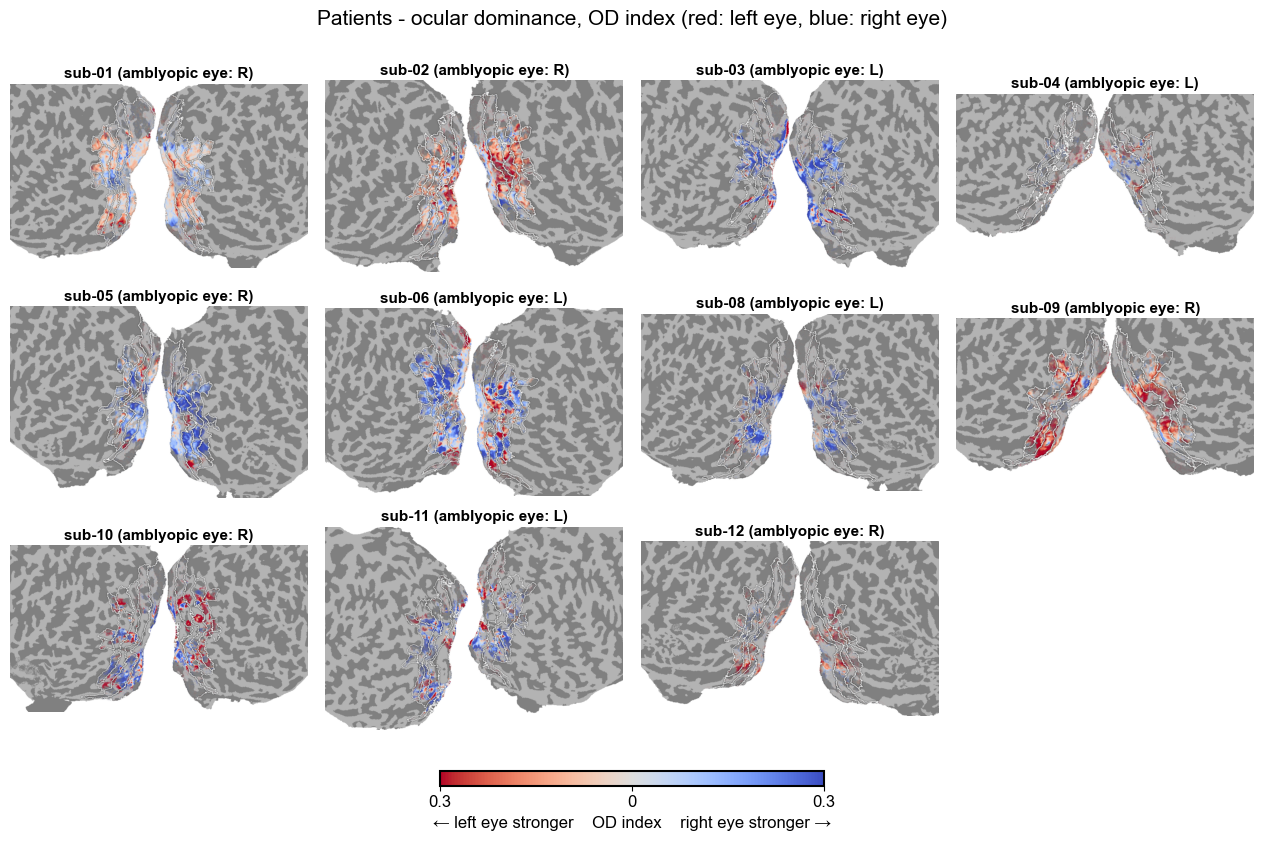

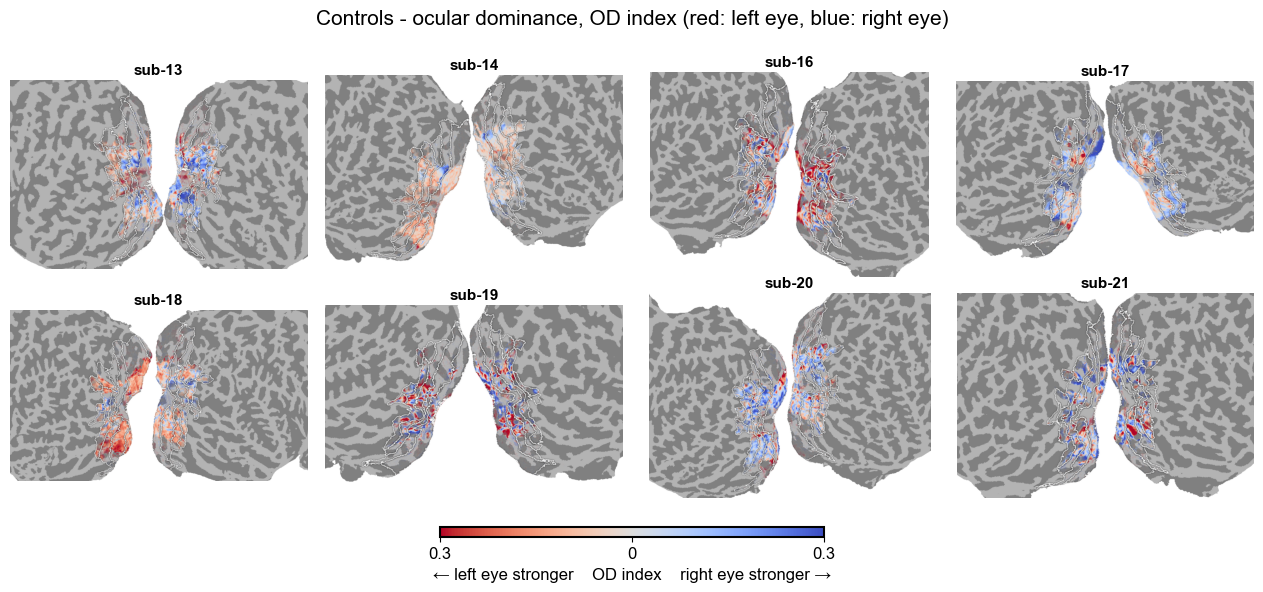

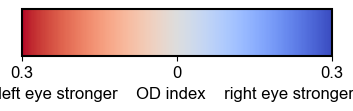

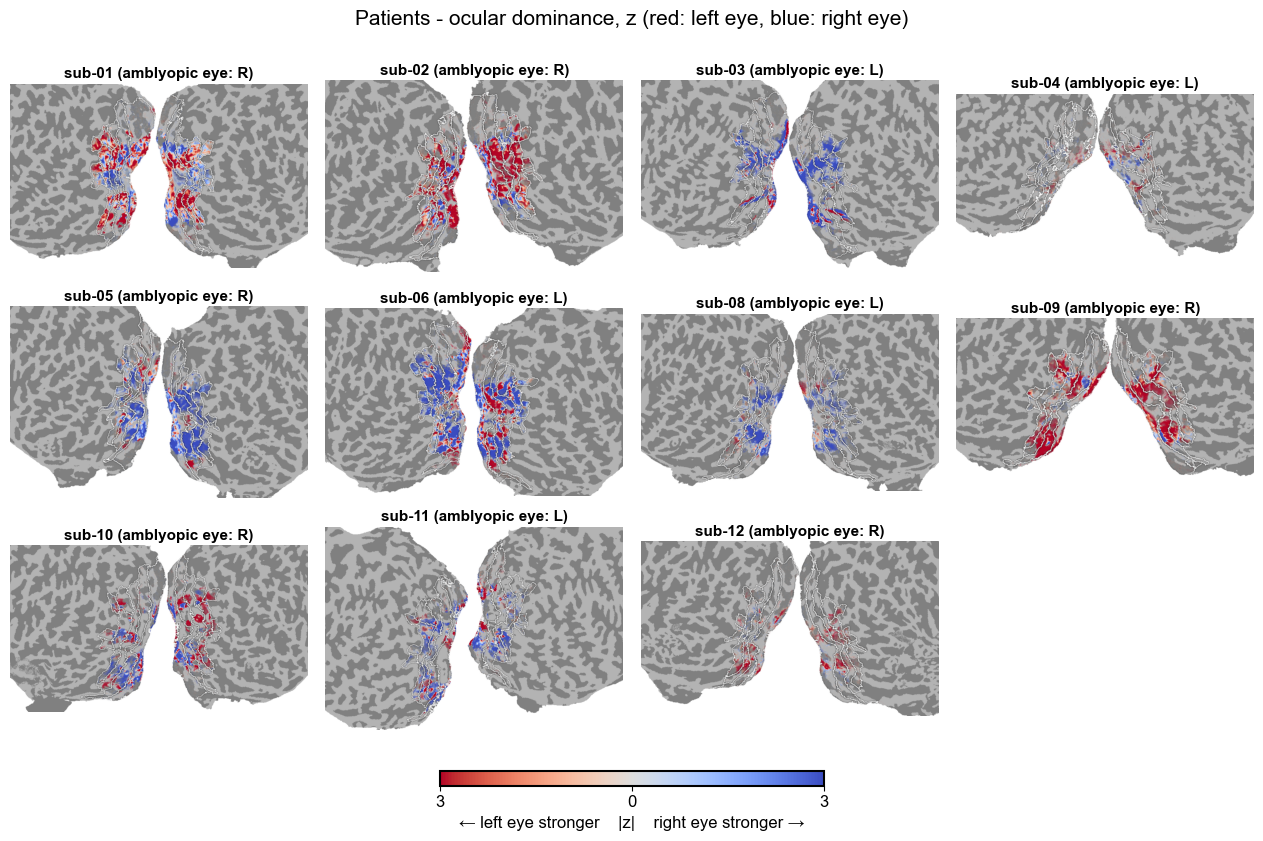

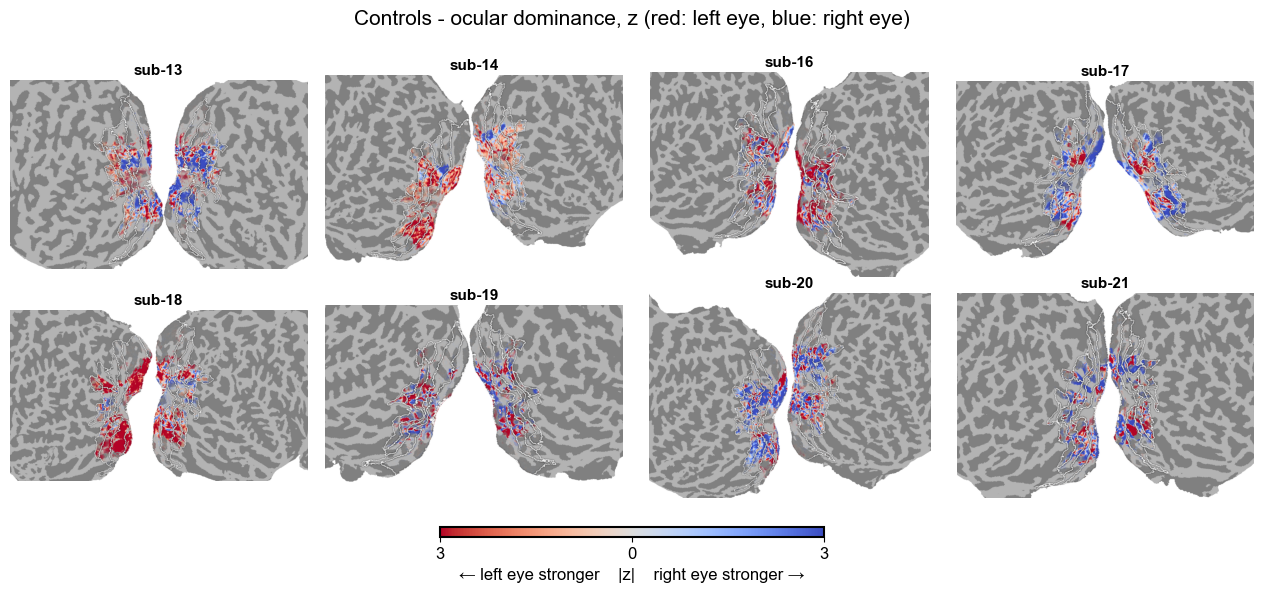

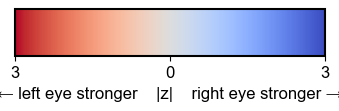

In [20]:
def colorbar_axes(fig, cax, vmax, label):
    cb = fig.colorbar(ScalarMappable(norm=mcolors.Normalize(-vmax, vmax), cmap=cmap_od), cax=cax, orientation='horizontal')
    cb.set_ticks([-vmax, 0, vmax])
    cb.set_ticklabels([str(vmax), '0', str(vmax)])
    cb.set_label(label)


def patch_grid(fns, group_subjects, title, fn_out, vmax, label, n_subj_per_row=4):
    """Assemble the saved patches, one panel per subject (both V1s in each panel)."""
    group_subjects = [s for s in group_subjects if s in fns]
    if not group_subjects:
        print('No patch available for: {}'.format(title))
        return
    n_rows = int(np.ceil(len(group_subjects) / n_subj_per_row))
    img_h, img_w = plt.imread(fns[group_subjects[0]]).shape[:2]
    panel_w = 3.2
    fig, axes = plt.subplots(n_rows, n_subj_per_row, squeeze=False,
                             figsize=(n_subj_per_row * panel_w, n_rows * (panel_w * img_h / img_w + 0.5)))
    for ax in axes.ravel():
        ax.axis('off')
    for i, s in enumerate(group_subjects):
        ax = axes[divmod(i, n_subj_per_row)]
        ax.imshow(plt.imread(fns[s]))
        label_s = s if s not in ambly_eye else '{} (amblyopic eye: {})'.format(s, ambly_eye[s])
        ax.set_title(label_s, fontsize=11, fontweight='bold', pad=4)
    fig.suptitle(title, fontsize=15, y=1.0)
    plt.tight_layout()
    colorbar_axes(fig, fig.add_axes([0.35, -0.04, 0.3, 0.02]), vmax, label)
    for ext in ['png', 'pdf']:
        fig.savefig('{}/{}.{}'.format(map_dir, fn_out, ext), dpi=300, bbox_inches='tight')
    plt.show()


for map_type, prm in map_types.items():
    name = 'OD index' if map_type == 'od' else 'z'
    patch_grid(patch_fns[map_type], [s for s in patients if s in subjects],
               'Patients - ocular dominance, {} (red: left eye, blue: right eye)'.format(name),
               'od_V1_patches_patients_glm-common_{}'.format(map_type), prm['vmax'], prm['label'])
    patch_grid(patch_fns[map_type], [s for s in controls if s in subjects],
               'Controls - ocular dominance, {} (red: left eye, blue: right eye)'.format(name),
               'od_V1_patches_controls_glm-common_{}'.format(map_type), prm['vmax'], prm['label'])

    # Stand-alone colour bar
    fig, ax = plt.subplots(figsize=(4, 0.6))
    colorbar_axes(fig, ax, prm['vmax'], prm['label'])
    for ext in ['png', 'pdf']:
        fig.savefig('{}/od_colorbar_glm-common_{}.{}'.format(map_dir, map_type, ext), dpi=300, bbox_inches='tight')
    plt.show()

## 9. Group figure: response of the amblyopic and fellow eye per ROI

Response of each eye = β of `glm_common` (% signal, 4 runs), median over the kept vertices of the ROI for each subject. Bars = median across subjects, error bars = 25th and 75th percentiles (as in the other pRF figures).

Eye conditions as in the pRF figures: `FE-LE` = fellow eye for patients / left eye for controls, `AE-RE` = amblyopic eye for patients / right eye for controls. FE-LE: solid bar, AE-RE: hatched bar; patients in the ROI colour, controls in grey.

In [21]:
from maths_utils import weighted_nan_median

# Optional reliability threshold on |z| (None = every kept vertex is counted)
z_th = None

# Table: R²-weighted percentage of vertices preferring each eye, per subject and ROI,
# then median and 25/75 percentiles across subjects
rows = []
for subject in subjects:
    s = run_sums[subject]
    b_L, se_L = glm_from_sums(s, 0, all_runs)
    b_R, se_R = glm_from_sums(s, 1, all_runs)
    with np.errstate(divide='ignore', invalid='ignore'):
        z_le_re = (b_L - b_R) / np.sqrt(se_L ** 2 + se_R ** 2)

    # Weights: mean pRF R² of both eyes
    rsq = np.nanmean([s['fit_L'][fit_maps.index('r_squared')],
                      s['fit_R'][fit_maps.index('r_squared')]], axis=0)
    rsq = np.clip(rsq, 0, None)

    # Preferred eye of each vertex
    left_pref = b_L > b_R
    right_pref = b_R > b_L
    if z_th is not None:
        left_pref = left_pref & (np.abs(z_le_re) > z_th)
        right_pref = right_pref & (np.abs(z_le_re) > z_th)

    # AE-RE / FE-LE: patients -> amblyopic / fellow eye, controls -> right / left eye
    if subject in patients and ambly_eye[subject] == 'L':
        pref_ae, pref_fe = left_pref, right_pref
    else:
        pref_ae, pref_fe = right_pref, left_pref

    for roi in rois_to_keep:
        mask = keep[subject] & (s['roi'] == roi) & np.isfinite(b_L) & np.isfinite(b_R)
        for eye_condition, pref in [('FE-LE', pref_fe), ('AE-RE', pref_ae)]:
            rows.append({'subject': subject,
                         'group': 'patient' if subject in patients else 'control',
                         'roi': roi,
                         'eye_condition': eye_condition,
                         'n_vertices': mask.sum(),
                         'pref_percent': 100 * np.sum(rsq[mask] * pref[mask]) / np.sum(rsq[mask])})
df_pref_subjects = pd.DataFrame(rows)

df_pref_group = df_pref_subjects.groupby(['group', 'roi', 'eye_condition']).pref_percent.agg(
    median='median',
    p25=lambda v: np.nanpercentile(v, 25),
    p75=lambda v: np.nanpercentile(v, 75),
    n_subjects='count').reset_index()

print(df_pref_group.pivot_table(index=['group', 'eye_condition'], columns='roi', values='median')
      .reindex(columns=rois_to_keep).round(1))

roi                      V1    V2    V3    V4   V3A   V3B   LO1   LO2
group   eye_condition                                                
control AE-RE          49.1  45.5  50.9  43.2  42.0  57.5  50.4  35.7
        FE-LE          50.9  54.5  49.1  56.8  58.0  42.5  49.6  64.3
patient AE-RE          44.4  34.7  28.7  29.2  30.3  19.2  23.7  32.6
        FE-LE          55.6  65.3  71.3  70.8  69.7  80.8  76.3  67.4


In [22]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from plot_utils import plotly_template

# General figure settings
template_specs = dict(axes_color="rgba(0, 0, 0, 1)",
                      axes_width=2,
                      axes_font_size=15,
                      bg_col="rgba(255, 255, 255, 1)",
                      font='Arial',
                      title_font_size=15,
                      rois_plot_width=1.5)
fig_template = plotly_template(template_specs)

roi_colors_rgb = analysis_info['roi_colors']
fig_margin = analysis_info['rois_fig_margin']
bar_width = analysis_info['rois_bar_width']
rois_plot_height = analysis_info['rois_plot_height']
rois_hor_spacing = 50
ctrl_color = 'rgb(150,150,150)'
group_labels = {'patient': 'Amblyopes', 'control': 'Controls'}
eye_conditions = ['FE-LE', 'AE-RE']
eye_patterns = {'FE-LE': '', 'AE-RE': '/'}
eye_legends = {'FE-LE': 'FE / LE', 'AE-RE': 'AE / RE'}
y_range = [0, 100]
y_ticks = np.linspace(0, 100, 5)

rows, cols = 1, len(rois_to_keep)
fig_height = rois_plot_height * 2 * rows + fig_margin[1] + fig_margin[3]
fig_width = bar_width * 4 * cols + fig_margin[0] + fig_margin[2] + (rois_hor_spacing * (cols - 1))
hor_spacing = rois_hor_spacing / (fig_width - fig_margin[0] - fig_margin[2])

fig = make_subplots(rows=rows, cols=cols,
                    subplot_titles=rois_to_keep,
                    shared_yaxes=False,
                    horizontal_spacing=hor_spacing)

for col_idx, roi in enumerate(rois_to_keep, start=1):
    for eye_condition in eye_conditions:
        df_eye = df_pref_group.loc[(df_pref_group.roi == roi) & (df_pref_group.eye_condition == eye_condition)]
        df_eye = df_eye.set_index('group').reindex(['patient', 'control'])

        fig.add_trace(go.Bar(x=[group_labels[group] for group in df_eye.index],
                             y=df_eye['median'],
                             name=eye_legends[eye_condition],
                             offsetgroup=eye_condition,
                             marker=dict(color=[roi_colors_rgb[roi], ctrl_color],
                                         pattern=dict(shape=eye_patterns[eye_condition],
                                                      fgcolor='rgba(0,0,0,1)',
                                                      bgcolor='rgba(0,0,0,0)',
                                                      size=8)),
                             error_y=dict(type='data',
                                          array=df_eye['p75'] - df_eye['median'],
                                          arrayminus=df_eye['median'] - df_eye['p25'],
                                          visible=True,
                                          thickness=2,
                                          width=0,
                                          color='rgba(0,0,0,1)'),
                             showlegend=False),
                      row=1, col=col_idx)



# Dummy bar traces for the legend
for eye_condition in eye_conditions:
    fig.add_trace(go.Bar(x=[None], y=[None],
                         name=eye_legends[eye_condition],
                         marker=dict(color='rgba(128,128,128,1)',
                                     pattern=dict(shape=eye_patterns[eye_condition],
                                                  fgcolor='rgba(0,0,0,1)',
                                                  bgcolor='rgba(0,0,0,0.3)',
                                                  size=8)),
                         showlegend=True),
                  row=1, col=1)

fig.update_xaxes(showline=True, ticklen=0, linecolor='rgba(255,255,255,0)', tickangle=0)
fig.update_yaxes(showline=True,
                 range=y_range,
                 tickvals=y_ticks,
                 ticktext=['{:.0f}'.format(t) for t in y_ticks],
                 showticklabels=True)
fig.update_yaxes(title_text='Percentage of vertex (%)', row=1, col=1)
fig.update_layout(barmode='group',
                  bargap=0.3,
                  bargroupgap=0.05,
                  height=fig_height,
                  width=fig_width,
                  template=fig_template,
                  legend=dict(orientation='h',
                              font_family=template_specs['font'],
                              font_size=template_specs['axes_font_size'],
                              x=1, y=1.15,
                              xanchor='right',
                              yanchor='bottom',
                              bgcolor='rgba(0,0,0,0)',
                              traceorder='normal',
                              itemwidth=30),
                  margin_l=fig_margin[0],
                  margin_t=fig_margin[1] + 40,
                  margin_r=fig_margin[2],
                  margin_b=fig_margin[3])
fig.show()
fig.write_image("/Users/uriel/Downloads/od.pdf")

## 10. Control: order of the eyes (which eye was scanned first)

Each eye was scanned in separate runs, so any global change between the two halves of the session (vigilance, fatigue, motion, adaptation) can look like ocular dominance. The order was alternated across subjects (`sourcedata/participant-mapping.md`), which cancels it on average but not within a subject, and only if the order is balanced between **fellow and amblyopic** eye (not only left and right).

Measure: R²-weighted % of vertices preferring the FE-LE eye (section 9), centred on 50. Tests per ROI:

- **controls**: % of vertices preferring the eye scanned first, vs 50 (Wilcoxon);
- **patients**: fellow eye scanned first vs second (Mann-Whitney);
- **all subjects**: linear model `pref_FE-LE − 50 = group + b · order` (order = +1 if the FE-LE eye was scanned first, −1 otherwise). `b` = advantage of the eye scanned first, in % points; the group effect is also given **adjusted for the order**.

In [23]:
# Which eye was scanned first (read only: sourcedata/participant-mapping.md + participant_mapping.tsv)
src_dir = '{}/{}/sourcedata'.format(main_dir, project_dir)
mapping = pd.read_csv('{}/participant_mapping.tsv'.format(src_dir), sep='\t', dtype=str).dropna(subset=['initials'])
initials_to_sub = {i.strip(): b.strip() for i, b in zip(mapping.initials, mapping.bids_name)}
first_eye = {}
with open('{}/participant-mapping.md'.format(src_dir)) as f:
    for line in f:
        if 'eye first' in line:
            initials, txt = line.split(',', 1)
            first_eye[initials_to_sub[initials.strip()]] = 'L' if 'LEFT' in txt.upper() else 'R'

# FE-LE eye: fellow eye for patients, left eye for controls
fe_le_eye = {s: ({'L': 'R', 'R': 'L'}[ambly_eye[s]] if s in patients else 'L') for s in subjects}
order = pd.DataFrame({'subject': subjects,
                      'group': ['patient' if s in patients else 'control' for s in subjects],
                      'first_eye': [first_eye[s] for s in subjects],
                      'fe_le_eye': [fe_le_eye[s] for s in subjects]})
order['fe_le_first'] = order.first_eye == order.fe_le_eye
print(order.to_string(index=False))
print()
print(order.groupby('group').fe_le_first.agg(fe_le_first='sum', n='count'))

subject   group first_eye fe_le_eye  fe_le_first
 sub-01 patient         L         L         True
 sub-02 patient         L         L         True
 sub-03 patient         L         R        False
 sub-04 patient         R         R         True
 sub-05 patient         R         L        False
 sub-06 patient         L         R        False
 sub-08 patient         R         R         True
 sub-09 patient         R         L        False
 sub-10 patient         R         L        False
 sub-11 patient         L         R        False
 sub-12 patient         R         L        False
 sub-13 control         L         L         True
 sub-14 control         R         L        False
 sub-16 control         R         L        False
 sub-17 control         R         L        False
 sub-18 control         R         L        False
 sub-19 control         L         L         True
 sub-20 control         R         L        False
 sub-21 control         L         L         True

         fe_le_firs

In [24]:
def ols(X, y):
    """OLS coefficients, their covariance and the residual degrees of freedom."""
    coef = np.linalg.lstsq(X, y, rcond=None)[0]
    dof = y.size - X.shape[1]
    cov = np.sum((y - X @ coef) ** 2) / dof * np.linalg.inv(X.T @ X)
    return coef, cov, dof


d_order = df_pref_subjects[df_pref_subjects.eye_condition == 'FE-LE'].merge(order, on=['subject', 'group'])
d_order['pref_fe_le'] = d_order.pref_percent - 50                                  # > 0: FE-LE eye preferred
d_order['pref_first'] = np.where(d_order.fe_le_first, d_order.pref_fe_le, -d_order.pref_fe_le)   # > 0: first eye preferred

rows = []
for roi in rois_to_keep:
    dr = d_order[d_order.roi == roi].dropna(subset=['pref_fe_le'])
    ctrl, pat = dr[dr.group == 'control'], dr[dr.group == 'patient']
    pat_fe, pat_ae = pat[pat.fe_le_first].pref_fe_le, pat[~pat.fe_le_first].pref_fe_le

    # All subjects: pref_fe_le = a_control * control + a_patient * patient + b * order
    X = np.column_stack([dr.group == 'control', dr.group == 'patient', np.where(dr.fe_le_first, 1, -1)]).astype(float)
    coef, cov, dof = ols(X, dr.pref_fe_le.values)
    c = np.array([-1, 1, 0])
    group_adj, group_adj_se = c @ coef, np.sqrt(c @ cov @ c)

    rows.append({'roi': roi,
                 'ctrl_first_eye_median': ctrl.pref_first.median(),
                 'p_ctrl_first_vs_50': stats.wilcoxon(ctrl.pref_first).pvalue,
                 'pat_FE_first_median': pat_fe.median(),
                 'pat_AE_first_median': pat_ae.median(),
                 'p_pat_FE_vs_AE_first': stats.mannwhitneyu(pat_fe, pat_ae).pvalue,
                 'first_eye_advantage_b': coef[2],
                 'p_b': 2 * stats.t.sf(abs(coef[2] / np.sqrt(cov[2, 2])), dof),
                 'group_effect_adjusted': group_adj,
                 'p_group_adjusted': 2 * stats.t.sf(abs(group_adj / group_adj_se), dof)})
order_stats = pd.DataFrame(rows).set_index('roi')
print('Values in % points (% of vertices − 50)')
order_stats.round(3)

Values in % points (% of vertices − 50)


,ctrl_first_eye_median,p_ctrl_first_vs_50,pat_FE_first_median,pat_AE_first_median,p_pat_FE_vs_AE_first,first_eye_advantage_b,p_b,group_effect_adjusted,p_group_adjusted
roi,,,,,,,,,
V1,-5.382,0.383,11.217,5.584,0.788,-1.143,0.785,2.471,0.763
V2,-5.347,0.195,16.275,15.295,1.000,-1.195,0.783,6.973,0.416
V3,-13.033,0.148,18.096,21.285,0.648,-4.228,0.408,12.695,0.211
V4,-0.350,0.945,19.613,20.759,1.000,0.163,0.971,13.015,0.151
V3A,-5.884,0.547,21.170,19.681,1.000,-2.038,0.668,14.941,0.120
V3B,-1.766,0.844,25.105,32.024,0.788,0.768,0.910,22.572,0.105
LO1,-10.240,0.547,26.058,26.310,0.927,-0.842,0.877,16.625,0.130
LO2,14.735,0.312,-2.484,31.908,0.412,0.543,0.935,5.222,0.687


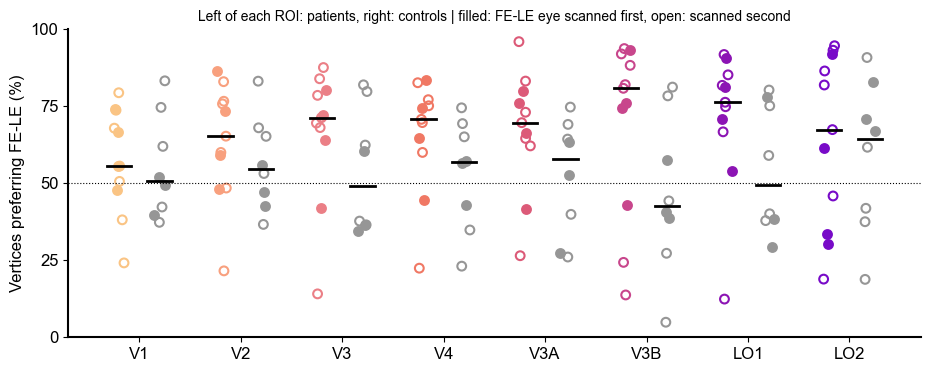

In [25]:
# Figure: % of vertices preferring the FE-LE eye, filled = FE-LE eye scanned first, open = scanned second
fig, ax = plt.subplots(figsize=(11, 4))
for g_i, (group, label) in enumerate([('patient', 'Patients'), ('control', 'Controls')]):
    for r_i, roi in enumerate(rois_to_keep):
        dr = d_order[(d_order.roi == roi) & (d_order.group == group)]
        x0 = r_i + (g_i - 0.5) * 0.4
        col = roi_colors[roi] if group == 'patient' else color_ctrl
        for first, face in [(True, col), (False, 'none')]:
            v = dr[dr.fe_le_first == first].pref_percent.values
            ax.scatter(x0 + np.random.uniform(-0.06, 0.06, v.size), v, s=40, facecolors=face, edgecolors=col, linewidths=1.5)
        ax.plot([x0 - 0.12, x0 + 0.12], [dr.pref_percent.median()] * 2, color='k', lw=2)
ax.axhline(50, color='k', lw=0.8, ls=':')
ax.set_xticks(range(len(rois_to_keep)))
ax.set_xticklabels(rois_to_keep)
ax.set_ylim(0, 100)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_ylabel('Vertices preferring FE-LE (%)')
ax.set_title('Left of each ROI: patients, right: controls | filled: FE-LE eye scanned first, open: scanned second', fontsize=10)
order_dir = '/Users/uriel/Desktop/fig_od/glm_common'
os.makedirs(order_dir, exist_ok=True)
for ext in ['png', 'pdf']:
    fig.savefig('{}/od_eye_order_control.{}'.format(order_dir, ext), dpi=300, bbox_inches='tight')
plt.show()

## 11. Control: circularity of the regressor

The prediction of each eye was fitted on the data of that eye, so the common regressor contains a bit of each eye's noise, which slightly inflates that eye's β. Control without any refit: each eye's data are regressed on the prediction of the **other eye only** (`cross`). The regressor is then fully independent of the noise of the eye being measured.

Three regressors compared (same vertices, same measure = R²-weighted % of vertices preferring the FE-LE eye):

- `own`: each eye on its own prediction (maximal circularity);
- `common`: the method used (mean of both);
- `cross`: each eye on the other eye's prediction (no circularity).

If the group effect is the same with `cross`, the circularity does not drive the result. Note that `cross` is conservative: if the pRF of one eye is estimated worse, the other eye is penalised.

The `cross` sums need one new reading of the data (pred + bold only), cached in `{sub}_od-glm-cross_runs.npz` in the same cache folder.

In [26]:
def extract_cross(subject):
    """Per-run sums of each eye's data on the other eye's z-scored prediction (same vertices as run_sums)."""
    t0 = time.time()
    cache_fn = '{}/{}_od-glm-cross_runs.npz'.format(cache_dir, subject)
    vert_idx = run_sums[subject]['vertex']
    preds, datas = {}, {}
    for e, eye in eyes.items():
        pred_h, data_h = [], []
        for hemi in ['L', 'R']:
            _, pred = load_surface(fn=file_tpl.format(pp_dir, subject, 'prfmodel/fit', subject, task, eye, hemi, 'prf-css_pred'))
            if hemi == 'L':
                n_vert_L = pred.shape[1]
                idx = vert_idx[vert_idx < n_vert_L]
            else:
                idx = vert_idx[vert_idx >= n_vert_L] - n_vert_L
            pred_h.append(pred[:, idx].astype(float))
            del pred
            _, data = load_surface(fn=file_tpl.format(pp_dir, subject, 'func/fmriprep_dct_psc_concat', subject, task, eye, hemi, 'bold'))
            data_h.append(data[:, idx].astype(float))
            del data
        preds[e] = np.hstack(pred_h)
        datas[e] = np.hstack(data_h)

    n_tr = preds['L'].shape[0]
    run_len = n_tr // n_runs
    sxy_cross, sxx_cross = np.zeros((2, n_runs, vert_idx.size)), np.zeros((2, n_runs, vert_idx.size))
    for r in range(n_runs):
        sl = slice(r * run_len, (r + 1) * run_len)
        z = {}
        for e in eyes:
            p = preds[e][sl]
            with np.errstate(divide='ignore', invalid='ignore'):
                z[e] = np.nan_to_num((p - p.mean(axis=0)) / p.std(axis=0))
        for i, e in enumerate(eyes):
            other = 'R' if e == 'L' else 'L'
            y = datas[e][sl]
            y = y - y.mean(axis=0)
            sxy_cross[i, r] = (z[other] * y).sum(axis=0)
            sxx_cross[i, r] = (z[other] ** 2).sum(axis=0)
    res = {'sxy_cross': sxy_cross, 'sxx_cross': sxx_cross}
    if use_cache:
        np.savez_compressed(cache_fn, **res)
    return subject, res, 'extracted ({:.0f} s)'.format(time.time() - t0)


t0 = time.time()
to_extract = []
for subject in subjects:
    cache_fn = '{}/{}_od-glm-cross_runs.npz'.format(cache_dir, subject)
    if use_cache and os.path.isfile(cache_fn):
        cache = np.load(cache_fn)
        run_sums[subject].update({k: cache[k] for k in cache.files})
        print('{}: cross sums loaded from cache'.format(subject))
    else:
        to_extract.append(subject)
if to_extract:
    print('Extracting {} subjects with {} parallel jobs'.format(len(to_extract), min(n_jobs, len(to_extract))))
    results = Parallel(n_jobs=min(n_jobs, len(to_extract)), verbose=10)(
        delayed(extract_cross)(subject) for subject in to_extract)
    for subject, res, status in results:
        run_sums[subject].update(res)
        print('{}: {}'.format(subject, status))
print('Total: {:.0f} s'.format(time.time() - t0))

Extracting 19 subjects with 1 parallel jobs


[Parallel(n_jobs=1)]: Done   1 tasks      | elapsed:  1.9min
[Parallel(n_jobs=1)]: Done   4 tasks      | elapsed:  7.4min
[Parallel(n_jobs=1)]: Done   7 tasks      | elapsed: 13.8min
[Parallel(n_jobs=1)]: Done  12 tasks      | elapsed: 22.3min
[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed: 30.6min


sub-01: extracted (112 s)
sub-02: extracted (117 s)
sub-03: extracted (120 s)
sub-04: extracted (94 s)
sub-05: extracted (121 s)
sub-06: extracted (136 s)
sub-08: extracted (128 s)
sub-09: extracted (122 s)
sub-10: extracted (104 s)
sub-11: extracted (82 s)
sub-12: extracted (93 s)
sub-13: extracted (110 s)
sub-14: extracted (100 s)
sub-16: extracted (108 s)
sub-17: extracted (98 s)
sub-18: extracted (103 s)
sub-19: extracted (90 s)
sub-20: extracted (101 s)
sub-21: extracted (76 s)
Total: 2014 s


In [27]:
def betas_regressor(s, regressor, runs=all_runs):
    """β of the left and right eye (all runs) with the 'common', 'own' or 'cross' regressor."""
    runs = list(runs)
    out = []
    for eye_i in range(2):
        if regressor == 'cross':
            sxy = s['sxy_cross'][eye_i, runs].sum(axis=0)
            sxx = s['sxx_cross'][eye_i, runs].sum(axis=0)
            with np.errstate(divide='ignore', invalid='ignore'):
                out.append(sxy / sxx)
        else:
            out.append(glm_from_sums(s, eye_i, runs, regressor)[0])
    return out


rows = []
for subject in subjects:
    s = run_sums[subject]
    rsq = np.clip(np.nanmean([s['fit_L'][fit_maps.index('r_squared')], s['fit_R'][fit_maps.index('r_squared')]], axis=0), 0, None)
    fe_left = fe_le_eye[subject] == 'L'
    for regressor in ['own', 'common', 'cross']:
        b_L, b_R = betas_regressor(s, regressor)
        pref_fe = (b_L > b_R) if fe_left else (b_R > b_L)
        for roi in rois_to_keep:
            mask = keep[subject] & (s['roi'] == roi) & np.isfinite(b_L) & np.isfinite(b_R)
            rows.append({'subject': subject, 'group': 'patient' if subject in patients else 'control', 'roi': roi,
                         'regressor': regressor,
                         'pref_fe_le': 100 * np.sum(rsq[mask] * pref_fe[mask]) / np.sum(rsq[mask])})
df_circ = pd.DataFrame(rows)

rows = []
for roi in rois_to_keep:
    row = {'roi': roi}
    wide = df_circ[df_circ.roi == roi].pivot(index='subject', columns='regressor', values='pref_fe_le')
    for regressor in ['own', 'common', 'cross']:
        d = df_circ[(df_circ.roi == roi) & (df_circ.regressor == regressor)]
        vp, vc = d[d.group == 'patient'].pref_fe_le, d[d.group == 'control'].pref_fe_le
        row['pat_{}'.format(regressor)] = vp.median()
        row['ctrl_{}'.format(regressor)] = vc.median()
        row['p_{}'.format(regressor)] = stats.mannwhitneyu(vp, vc).pvalue
    row['rho_common_cross'] = stats.spearmanr(wide['common'], wide['cross']).correlation
    rows.append(row)
circ_stats = pd.DataFrame(rows).set_index('roi')
print('Median % of vertices preferring FE-LE, patients vs controls (Mann-Whitney p), per regressor')
circ_stats.round(3)

Median % of vertices preferring FE-LE, patients vs controls (Mann-Whitney p), per regressor


,pat_own,ctrl_own,p_own,pat_common,ctrl_common,p_common,pat_cross,ctrl_cross,p_cross,rho_common_cross
roi,,,,,,,,,,
V1,56.223,50.993,0.778,55.649,50.874,0.717,56.427,51.368,0.600,0.993
V2,64.807,54.793,0.272,65.295,54.474,0.272,64.950,54.404,0.395,0.991
V3,71.855,49.278,0.109,71.285,49.083,0.129,69.634,47.917,0.152,0.984
V4,72.367,56.479,0.041,70.759,56.836,0.062,67.896,57.765,0.238,0.912
V3A,70.151,58.293,0.109,69.681,57.990,0.075,69.687,50.450,0.109,0.967
V3B,78.344,39.075,0.091,80.837,42.516,0.091,78.522,51.348,0.091,0.988
LO1,78.590,50.697,0.062,76.310,49.564,0.091,71.064,47.968,0.238,0.919
LO2,67.078,61.817,0.395,67.421,64.342,0.600,64.402,66.042,0.840,0.970


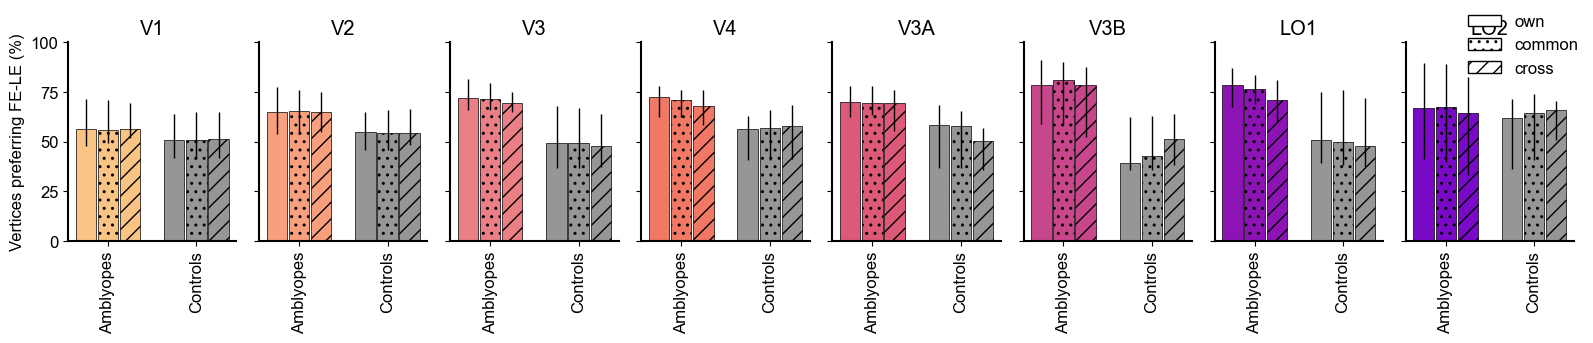

In [28]:
# Figure: group median and 25-75 percentiles of the % of vertices preferring FE-LE, for the three regressors
regs = ['own', 'common', 'cross']
fig, axes = plt.subplots(1, len(rois_to_keep), figsize=(2 * len(rois_to_keep), 3.5), sharey=True)
for ax, roi in zip(axes, rois_to_keep):
    for g_i, group in enumerate(['patient', 'control']):
        for r_i, regressor in enumerate(regs):
            v = df_circ[(df_circ.roi == roi) & (df_circ.group == group) & (df_circ.regressor == regressor)].pref_fe_le
            x = g_i + (r_i - 1) * 0.25
            col = roi_colors[roi] if group == 'patient' else color_ctrl
            ax.bar(x, v.median(), width=0.23, color=col, hatch=['', '..', '//'][r_i], edgecolor='k', linewidth=0.5)
            ax.errorbar(x, v.median(), yerr=[[v.median() - np.nanpercentile(v, 25)], [np.nanpercentile(v, 75) - v.median()]],
                        color='k', lw=1)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Amblyopes', 'Controls'], rotation=90)
    ax.set_title(roi)
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100])
axes[0].set_ylabel('Vertices preferring FE-LE (%)')
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, facecolor='w', edgecolor='k', hatch=h) for h in ['', '..', '//']],
           labels=['own', 'common', 'cross'], loc='upper right', frameon=False)
plt.tight_layout()
for ext in ['png', 'pdf']:
    fig.savefig('{}/od_circularity_control.{}'.format(order_dir, ext), dpi=300, bbox_inches='tight')
plt.show()